

# **StyleBot – Entrega 1**

Integración de aprendizaje automático supervisado y no supervisado

Integrantes:
- Krysto Alberto Adan Jauregui Zuñiga: Coordinador del proyecto y responsable de datos

- Jacqueline Soto: Responsable de integración, documentación y demostración

- Juan José Aranda Flores: Responsable de redes neuronales (CNN)

- Luis Ángel Mendosa Gaytan: Responsable de simulación y aprendizaje por refuerzo

- Ángel Uriel Martínez Godinez: Responsable de aprendizaje automático clásico


---


Objetivo del proyecto:

Desarrollar un sistema capaz de identificar diferentes tipos de prendas de ropa mediante imágenes, utilizando técnicas de aprendizaje automático.



# **1. Carga de datos**

    Preparación y carga del conjunto de datos Fashion-MNIST.

    - Responsable: Krysto Alberto Adan Jauregui Zuñiga
    - Estado: Completo
    - Archivo del que proviene el trabajo: 01_datos.ipynb


  **Carga común para todo el equipo:**

    Esta celda define las categorías y las funciones. Todos deben conservarla
    igual. `X` contiene imágenes y `y` las categorías correctas.

    La prueba oficial tiene 10,000 imágenes. De las otras 60,000 apartamos 20 % para validación:
    quedan 48,000 para entrenamiento y 12,000 para validación. `stratify` conserva la proporción de
    las categorías y la semilla 42 fija la división. Los píxeles ya quedan normalizados entre 0 y 1;
    no vuelvas a dividirlos entre 255.

In [12]:
import numpy as np
from sklearn.model_selection import train_test_split

SEMILLA = 42
CATEGORIAS = [
    "Camiseta", "Pantalón", "Suéter", "Vestido", "Abrigo",
    "Sandalia", "Camisa", "Tenis", "Bolso", "Botín"
]

def preparar_datos_stylebot(X_base, y_base, X_prueba, y_prueba):
    """Divide los 60,000 ejemplos originales y conserva la prueba oficial."""
    assert X_base.shape == (60000, 28, 28)
    assert y_base.shape == (60000,)
    assert X_prueba.shape == (10000, 28, 28)
    assert y_prueba.shape == (10000,)
    assert X_base.dtype == np.uint8 and X_prueba.dtype == np.uint8

    # Los índices permiten identificar exactamente las imágenes de cada parte.
    indices = np.arange(len(y_base), dtype=np.int64)
    idx_train, idx_val = train_test_split(
        indices, test_size=0.20, random_state=SEMILLA, stratify=y_base
    )

    # Normalizar una sola vez: uint8 de 0 a 255 -> float32 de 0 a 1.
    datos = {
        "X_train": X_base[idx_train].astype(np.float32) / np.float32(255.0),
        "y_train": y_base[idx_train].copy(),
        "X_val": X_base[idx_val].astype(np.float32) / np.float32(255.0),
        "y_val": y_base[idx_val].copy(),
        "X_test": X_prueba.astype(np.float32) / np.float32(255.0),
        "y_test": y_prueba.copy(),
        "idx_train": idx_train,
        "idx_val": idx_val,
        # Estos índices pertenecen al archivo de prueba, no al de entrenamiento.
        "idx_test": np.arange(len(y_prueba), dtype=np.int64),
    }
    return datos

def cargar_datos_stylebot():
    """Descarga Fashion-MNIST automáticamente mediante TensorFlow/Keras."""
    from tensorflow.keras.datasets import fashion_mnist
    (X_base, y_base), (X_prueba, y_prueba) = fashion_mnist.load_data()
    return preparar_datos_stylebot(X_base, y_base, X_prueba, y_prueba)


**Descargar y preparar Fashion MNIST:**
    
    Ejecuta la siguiente celda. `fashion_mnist.load_data()` descarga automáticamente los archivos oficiales a través
    de TensorFlow/Keras.

    Esperamos estas formas: entrenamiento `(48000, 28, 28)`, validación `(12000, 28, 28)` y prueba `(10000, 28, 28)`.
    La descarga puede tardar la primera vez.

In [13]:
datos = cargar_datos_stylebot()
X_train, y_train = datos["X_train"], datos["y_train"]
X_val, y_val = datos["X_val"], datos["y_val"]
X_test, y_test = datos["X_test"], datos["y_test"]

print("Entrenamiento:", X_train.shape, y_train.shape)
print("Validación:   ", X_val.shape, y_val.shape)
print("Prueba:       ", X_test.shape, y_test.shape)
print("Píxeles:", X_train.dtype, "de", X_train.min(), "a", X_train.max())

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Entrenamiento: (48000, 28, 28) (48000,)
Validación:    (12000, 28, 28) (12000,)
Prueba:        (10000, 28, 28) (10000,)
Píxeles: float32 de 0.0 a 1.0


**Comprobar la división y los valores:**

    Las instrucciones `assert` detienen la ejecución si algo no coincide con lo esperado. Conservamos los índices de
    entrenamiento y validación para verificar que no se mezclaron. Los índices de prueba pertenecen a un archivo diferente.

    Revisamos forma, cantidad, rango, valores no finitos y categorías. Esto no equivale a una inspección exhaustiva de daños
    visuales ni a una búsqueda de duplicados de contenido.

In [14]:
# Esta comprobación NO evalúa modelos: verifica la preparación de datos.
assert len(np.intersect1d(datos["idx_train"], datos["idx_val"])) == 0
assert len(np.union1d(datos["idx_train"], datos["idx_val"])) == 60000

comprobaciones = []
for nombre, X, y, cantidad in [
    ("entrenamiento", X_train, y_train, 48000),
    ("validacion", X_val, y_val, 12000),
    ("prueba", X_test, y_test, 10000),
]:
    assert X.shape == (cantidad, 28, 28)
    assert y.shape == (cantidad,)
    assert X.dtype == np.float32
    assert np.isfinite(X).all()
    assert X.min() >= 0.0 and X.max() <= 1.0
    assert np.isin(y, np.arange(10)).all()
    conteos = np.bincount(y, minlength=10)
    assert np.all(conteos == cantidad // 10)
    comprobaciones.append({
        "conjunto": nombre, "imagenes": cantidad,
        "forma_imagen": "28x28", "tipo_pixeles": str(X.dtype),
        "minimo": float(X.min()), "maximo": float(X.max()),
        "valores_no_finitos": int((~np.isfinite(X)).sum()),
        "etiquetas_invalidas": int((~np.isin(y, np.arange(10))).sum()),
    })
    print(nombre, "OK:", cantidad, "imágenes;", conteos.tolist(), "por categoría")

print("OK: entrenamiento y validación no comparten índices.")
print("La prueba conserva las 10,000 imágenes del archivo oficial de prueba.")
print("Estas revisiones no demuestran ausencia de imágenes duplicadas o problemas visuales.")


entrenamiento OK: 48000 imágenes; [4800, 4800, 4800, 4800, 4800, 4800, 4800, 4800, 4800, 4800] por categoría
validacion OK: 12000 imágenes; [1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200] por categoría
prueba OK: 10000 imágenes; [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000] por categoría
OK: entrenamiento y validación no comparten índices.
La prueba conserva las 10,000 imágenes del archivo oficial de prueba.
Estas revisiones no demuestran ausencia de imágenes duplicadas o problemas visuales.


# **2. Análisis exploratorio**

    Exploración de las imágenes, categorías y distribución de los datos.
    
    - Responsable: Krysto Alberto Adan Jauregui Zuñiga
    - Estado: Completo
    - Archivo del que proviene el trabajo: 01_datos.ipynb

**Ver las categorías y sus cantidades:**

    Los números tienen el mismo significado para todos los integrantes. Camiseta es 0 y camisa es 6; no deben
    intercambiarse. Con esta división esperamos 4,800 imágenes de entrenamiento, 1,200 de validación y 1,000
    de prueba por categoría.

In [15]:
print("ID | Categoría | Entrenamiento | Validación | Prueba")
conteo_clases = []
for identificador, categoria in enumerate(CATEGORIAS):
    fila = {
        "id": identificador, "categoria": categoria,
        "entrenamiento": int(np.sum(y_train == identificador)),
        "validacion": int(np.sum(y_val == identificador)),
        "prueba": int(np.sum(y_test == identificador)),
    }
    conteo_clases.append(fila)
    print(f"{identificador:2} | {categoria:9} | {fila['entrenamiento']:5} | {fila['validacion']:5} | {fila['prueba']:5}")


ID | Categoría | Entrenamiento | Validación | Prueba
 0 | Camiseta  |  4800 |  1200 |  1000
 1 | Pantalón  |  4800 |  1200 |  1000
 2 | Suéter    |  4800 |  1200 |  1000
 3 | Vestido   |  4800 |  1200 |  1000
 4 | Abrigo    |  4800 |  1200 |  1000
 5 | Sandalia  |  4800 |  1200 |  1000
 6 | Camisa    |  4800 |  1200 |  1000
 7 | Tenis     |  4800 |  1200 |  1000
 8 | Bolso     |  4800 |  1200 |  1000
 9 | Botín     |  4800 |  1200 |  1000


**Guardar las tablas y las reglas del equipo:**

    Se guardan categorías, conteos, comprobaciones, índices y un protocolo con la semilla,
    las versiones y las huellas de la división. El archivo de índices es pequeño: no
    contiene las imágenes.

    Si dos integrantes usan diferentes versiones, comparen las huellas en
    `protocolo_datos.json`. Si no coinciden, acuerden una misma versión o reutilicen
    los índices del líder antes de comparar modelos.

In [16]:
from pathlib import Path
import csv
import hashlib
import importlib.metadata
import json
import zipfile

# Todos los resultados se escriben en esta carpeta, dentro de la sesión actual.
CARPETA_SALIDA = Path("StyleBot_datos_generados")
for subcarpeta in ["datos", "resultados/tablas", "resultados/graficas"]:
    (CARPETA_SALIDA / subcarpeta).mkdir(parents=True, exist_ok=True)

def guardar_csv(ruta, filas):
    with ruta.open("w", newline="", encoding="utf-8-sig") as archivo:
        escritor = csv.DictWriter(archivo, fieldnames=list(filas[0].keys()))
        escritor.writeheader()
        escritor.writerows(filas)

guardar_csv(CARPETA_SALIDA / "datos/categorias.csv", [
    {"id": i, "categoria": nombre} for i, nombre in enumerate(CATEGORIAS)
])
guardar_csv(CARPETA_SALIDA / "resultados/tablas/conteo_clases.csv", conteo_clases)
guardar_csv(CARPETA_SALIDA / "resultados/tablas/verificacion_datos.csv", comprobaciones)

np.savez_compressed(
    CARPETA_SALIDA / "datos/particiones_semilla42.npz",
    idx_train=datos["idx_train"], idx_val=datos["idx_val"], idx_test=datos["idx_test"]
)

versiones = {}
for paquete in ["numpy", "scikit-learn", "matplotlib", "tensorflow"]:
    try:
        versiones[paquete] = importlib.metadata.version(paquete)
    except importlib.metadata.PackageNotFoundError:
        versiones[paquete] = "no detectado en este entorno"

huellas_indices = {
    nombre: hashlib.sha256(datos[nombre].astype("<i8").tobytes()).hexdigest()
    for nombre in ["idx_train", "idx_val", "idx_test"]
}
protocolo = {
    "dataset": "Fashion-MNIST", "semilla": SEMILLA,
    "entrenamiento": 48000, "validacion": 12000, "prueba": 10000,
    "origen_train_val": "60,000 imágenes oficiales de entrenamiento",
    "origen_test": "10,000 imágenes oficiales de prueba, conservadas",
    "separacion": "train_test_split, test_size=0.20, stratify=y_base",
    "forma_imagen": [28, 28], "normalizacion": "float32 / 255.0, una sola vez",
    "categorias": {str(i): nombre for i, nombre in enumerate(CATEGORIAS)},
    "sha256_indices": huellas_indices, "versiones": versiones,
}
(CARPETA_SALIDA / "datos/protocolo_datos.json").write_text(
    json.dumps(protocolo, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("Resultados guardados en:", CARPETA_SALIDA.resolve())
print("Huella de la división de entrenamiento:", huellas_indices["idx_train"])


Resultados guardados en: /content/StyleBot_datos_generados
Huella de la división de entrenamiento: 1c0cffec1476c830767b282ef3e3354d14cb1e3e2ecb436f13ee8537f0de19c9


**Mostrar ejemplos y distribución:**

    Estas figuras sirven para revisar que las categorías y sus imágenes tengan sentido.
    La selección de ejemplos utiliza únicamente entrenamiento.

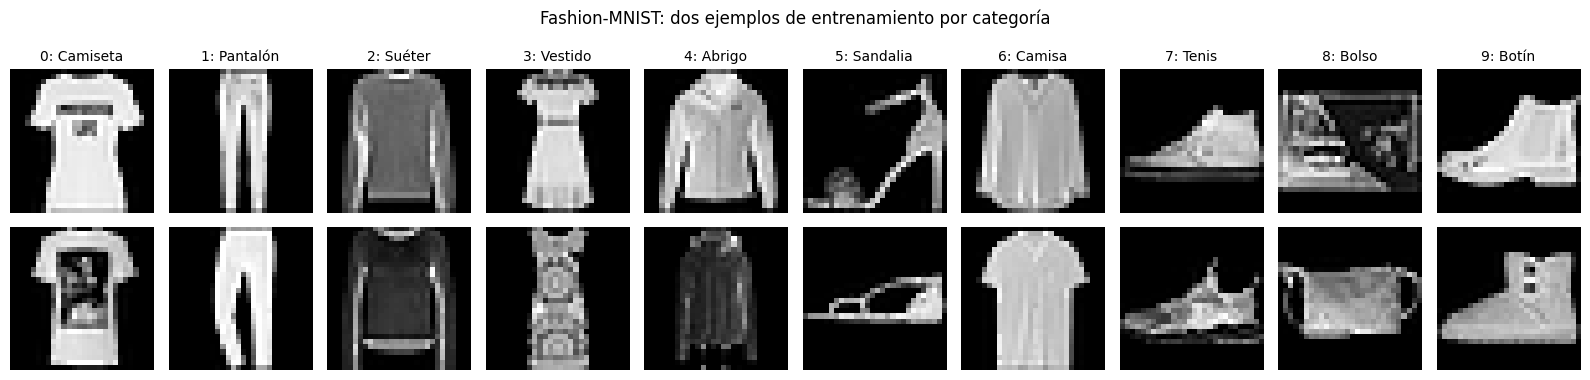

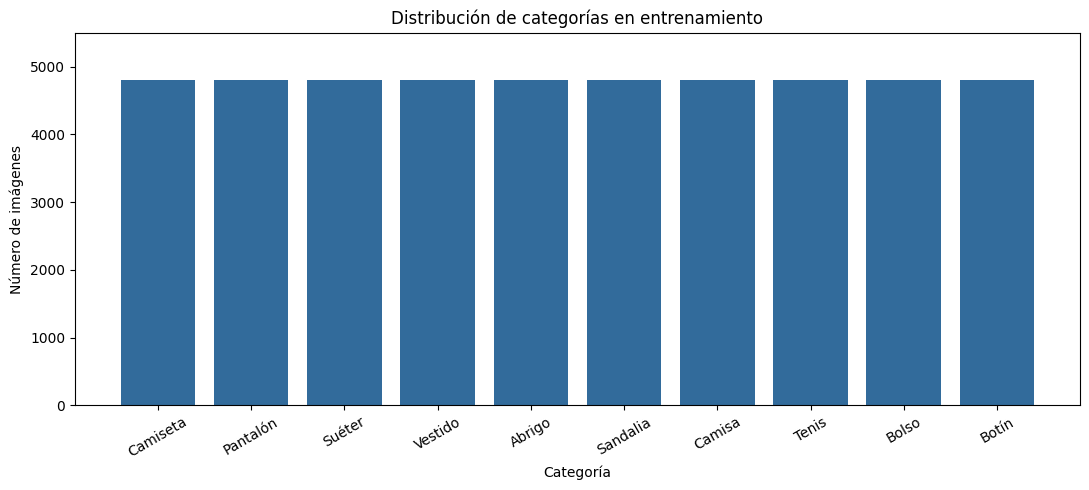

In [17]:
import matplotlib.pyplot as plt

# Solo usamos entrenamiento para elegir los ejemplos exploratorios.
fig, ejes = plt.subplots(2, 10, figsize=(16, 4))
for categoria_id, nombre in enumerate(CATEGORIAS):
    ejemplos = np.flatnonzero(y_train == categoria_id)[:2]
    for fila, indice in enumerate(ejemplos):
        ejes[fila, categoria_id].imshow(X_train[indice], cmap="gray", vmin=0, vmax=1)
        ejes[fila, categoria_id].axis("off")
        if fila == 0:
            ejes[fila, categoria_id].set_title(f"{categoria_id}: {nombre}", fontsize=10)
fig.suptitle("Fashion-MNIST: dos ejemplos de entrenamiento por categoría")
fig.tight_layout()
fig.savefig(CARPETA_SALIDA / "resultados/graficas/ejemplos_prendas.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(CATEGORIAS, np.bincount(y_train, minlength=10), color="#326b9b")
ax.set_title("Distribución de categorías en entrenamiento")
ax.set_xlabel("Categoría")
ax.set_ylabel("Número de imágenes")
ax.tick_params(axis="x", rotation=30)
ax.set_ylim(0, 5500)
fig.tight_layout()
fig.savefig(CARPETA_SALIDA / "resultados/graficas/distribucion_entrenamiento.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)


**Descargar los resultados para el equipo:**

    La siguiente celda descarga un ZIP con las tablas, figuras y protocolo. Guárdalo en
    tu computadora y extráelo antes de subir los archivos a GitHub.

    Además, descarga este notebook desde Archivo y Descargar como `.ipynb` después de
    ejecutarlo. Ese archivo conservará las salidas de tu sesión. El ZIP de resultados no
    incluye automáticamente el notebook.

In [ ]:
ruta_zip = Path("StyleBot_datos_generados.zip")
with zipfile.ZipFile(ruta_zip, "w", zipfile.ZIP_DEFLATED) as comprimido:
    for ruta in sorted(CARPETA_SALIDA.rglob("*")):
        if ruta.is_file():
            comprimido.write(ruta, ruta.relative_to(CARPETA_SALIDA))
print("Archivo preparado:", ruta_zip.resolve())

# En Colab, esta línea ofrece el ZIP para descargar a tu computadora.
try:
    from google.colab import files
except ImportError:
    print("Fuera de Colab: abre el ZIP en la ruta indicada arriba.")
else:
    files.download(str(ruta_zip))


Archivo preparado: /content/StyleBot_datos_generados.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Fuentes:**

    TensorFlow. Fashion-MNIST load_data. https://www.tensorflow.org/api_docs/python/tf/keras/datasets/fashion_mnist/load_data
    TensorFlow. Basic classification. https://www.tensorflow.org/tutorials/keras/classification
    Scikit-learn. train_test_split. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
    Zalando Research. Fashion-MNIST. https://github.com/zalandoresearch/fashion-mnist

# **3. Características de las imágenes**

    Preparación de las características que utilizarán los modelos.

    - Responsable: Juan José Aranda Flores
    - Estado: Completo
    - Archivo del que proviene el trabajo: 02_caracteristicas.ipynb

**Conversión a píxeles aplanados (Flattening):**

    Transformación de las matrices de imágenes de  28×28  píxeles en vectores unidimensionales de 784 características,
    conservando el orden de los conjuntos de entrenamiento, validación y prueba.

In [18]:
def aplanar_imagenes(X):
    return X.reshape(X.shape[0], -1)

X_train_flat = aplanar_imagenes(X_train)
X_val_flat = aplanar_imagenes(X_val)
X_test_flat = aplanar_imagenes(X_test)
print("Forma aplanada:", X_train_flat.shape) # Debe dar (48000, 784)

Forma aplanada: (48000, 784)


**Reducción de dimensionalidad con PCA:**

    Demostración de reducción a 50 componentes principales ajustando únicamente con el conjunto de entrenamiento.
    Nota para Aprendizaje Clásico: Durante la validación cruzada y el ajuste de hiperparámetros (GridSearchCV), el
    escalado y PCA(n_components=50, random_state=42) deben colocarse dentro de un Pipeline junto con el clasificador
    para evitar fuga de datos (data leakage).

In [19]:
from sklearn.decomposition import PCA

# Función reutilizable para preparar PCA (ajustando SOLO con entrenamiento)
def aplicar_pca(X_train_f, X_val_f, X_test_f, n_componentes=50):
    pca = PCA(n_components=n_componentes, random_state=42)

    # Regla de oro: fit_transform solo en entrenamiento, transform en validación y prueba
    X_train_pca = pca.fit_transform(X_train_f)
    X_val_pca = pca.transform(X_val_f)
    X_test_pca = pca.transform(X_test_f)

    varianza = pca.explained_variance_ratio_.sum()
    print(f"Varianza conservada con {n_componentes} componentes: {varianza:.4f} ({varianza*100:.2f}%)")
    return X_train_pca, X_val_pca, X_test_pca, pca

# Ejecutar PCA
X_train_pca, X_val_pca, X_test_pca, modelo_pca = aplicar_pca(X_train_flat, X_val_flat, X_test_flat, 50)
print("Forma de entrenamiento con PCA:", X_train_pca.shape) # Debe dar (48000, 50)

Varianza conservada con 50 componentes: 0.8627 (86.27%)
Forma de entrenamiento con PCA: (48000, 50)


**Extracción de características con HOG (Histogram of Oriented Gradients):**

    Obtención de descriptores de gradientes orientados para capturar bordes y contornos locales de las prendas
    (configuración: 9 orientaciones, celdas de  4×4  píxeles y bloques de  2×2  celdas).

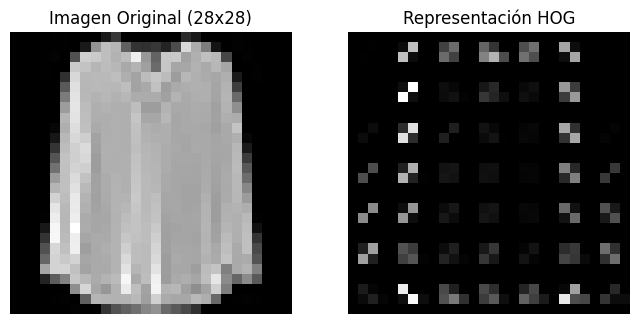

Cantidad de características HOG por imagen: 1296
Extrayendo HOG de entrenamiento, validación y prueba (esto toma ~1-2 min)...
Forma HOG entrenamiento: (48000, 1296)
Forma HOG validación:    (12000, 1296)
Forma HOG prueba:        (10000, 1296)


In [21]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import hog

# 1. Prueba visual con 1 sola imagen
img_ejemplo = X_train[0]
vector_hog_ej, img_hog_vis = hog(
    img_ejemplo,
    orientations=9,
    pixels_per_cell=(4, 4),
    cells_per_block=(2, 2),
    visualize=True
)

# Dibujar imagen original vs HOG
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(img_ejemplo, cmap='gray')
ax[0].set_title("Imagen Original (28x28)")
ax[0].axis('off')

ax[1].imshow(img_hog_vis, cmap='gray')
ax[1].set_title("Representación HOG")
ax[1].axis('off')
plt.show()

print("Cantidad de características HOG por imagen:", len(vector_hog_ej))

# 2. Función reutilizable para aplicar HOG a todo un conjunto de imágenes
def extraer_hog(imagenes):
    lista_hog = []
    for img in imagenes:
        caracteristicas = hog(
            img,
            orientations=9,
            pixels_per_cell=(4, 4),
            cells_per_block=(2, 2),
            visualize=False
        )
        lista_hog.append(caracteristicas)
    return np.array(lista_hog, dtype=np.float32)

# Extraer HOG de los 3 conjuntos
print("Extrayendo HOG de entrenamiento, validación y prueba (esto toma ~1-2 min)...")
X_train_hog = extraer_hog(X_train)
X_val_hog = extraer_hog(X_val)
X_test_hog = extraer_hog(X_test)

print("Forma HOG entrenamiento:", X_train_hog.shape)
print("Forma HOG validación:   ", X_val_hog.shape)
print("Forma HOG prueba:       ", X_test_hog.shape)

**Extracción de características con Momentos de Hu:**

    Cálculo de los momentos centrales, normalizados y los 7 momentos invariantes de Hu por imagen para resumir la
    forma geométrica global de cada prenda, verificando la ausencia de valores nulos (NaN) o infinitos (Inf).

In [22]:
from skimage.measure import moments_central, moments_normalized, moments_hu

# Función reutilizable para extraer los 7 momentos de Hu por imagen
def extraer_momentos_hu(imagenes):
    lista_hu = []
    for img in imagenes:
        # Aseguramos tipo float64 para el cálculo exacto de momentos
        img_f = img.astype(np.float64)
        mu = moments_central(img_f)
        nu = moments_normalized(mu)
        hu = moments_hu(nu)
        lista_hu.append(hu)
    return np.array(lista_hu, dtype=np.float32)

# Extraer Momentos de Hu en los 3 conjuntos
X_train_hu = extraer_momentos_hu(X_train)
X_val_hu = extraer_momentos_hu(X_val)
X_test_hu = extraer_momentos_hu(X_test)

print("Forma Momentos de Hu (Entrenamiento):", X_train_hu.shape) # Debe dar (48000, 7)
print("Forma Momentos de Hu (Validación):   ", X_val_hu.shape)   # Debe dar (12000, 7)
print("Forma Momentos de Hu (Prueba):       ", X_test_hu.shape)  # Debe dar (10000, 7)

# Comprobar que no existan valores faltantes (NaN) o infinitos (Inf)
print("¿Hay valores NaN en Hu?:", np.isnan(X_train_hu).sum() + np.isnan(X_val_hu).sum() + np.isnan(X_test_hu).sum())
print("¿Hay valores Inf en Hu?:", np.isinf(X_train_hu).sum() + np.isinf(X_val_hu).sum() + np.isinf(X_test_hu).sum())

Forma Momentos de Hu (Entrenamiento): (48000, 7)
Forma Momentos de Hu (Validación):    (12000, 7)
Forma Momentos de Hu (Prueba):        (10000, 7)
¿Hay valores NaN en Hu?: 0
¿Hay valores Inf en Hu?: 0


**Comparación de representaciones y características:**

    Resumen comparativo del número de características generadas por cada método y las dimensiones resultantes.

In [23]:
import pandas as pd

tabla_caracteristicas = pd.DataFrame({
    "Representación / Método": [
        "Píxeles aplanados (Flattening)",
        "Reducción PCA",
        "Descriptor HOG",
        "Momentos de Hu"
    ],
    "Número de características por imagen": [
        X_train_flat.shape[1],
        X_train_pca.shape[1],
        X_train_hog.shape[1],
        X_train_hu.shape[1]
    ],
    "Dimensiones en Entrenamiento": [
        str(X_train_flat.shape),
        str(X_train_pca.shape),
        str(X_train_hog.shape),
        str(X_train_hu.shape)
    ]
})

display(tabla_caracteristicas)

,Representación / Método,Número de características por imagen,Dimensiones en Entrenamiento
0,Píxeles aplanados (Flattening),784,"(48000, 784)"
1,Reducción PCA,50,"(48000, 50)"
2,Descriptor HOG,1296,"(48000, 1296)"
3,Momentos de Hu,7,"(48000, 7)"


**Fuentes:**

    Scikit-learn Developers. PCA (Principal Component Analysis). https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html
    Scikit-image Developers. Histogram of Oriented Gradients (skimage.feature.hog). https://scikit-image.org/docs/stable/auto_examples/features_detection/plot_hog.html
    Scikit-image Developers. Image Moments & Hu Moments (skimage.measure). https://scikit-image.org/docs/stable/api/skimage.measure.html

# **4. Aprendizaje supervisado**

    Entrenamiento y comparación de los modelos de clasificación.

    - Responsable: Ángel Uriel Martínez Godinez
    - Estado: Completo
    - Archivo del que proviene el trabajo: 03_modelos.ipynb

Entrenamiento: (48000, 784)
Validación: (12000, 784)
Prueba: (10000, 784)

RESULTADO PRELIMINAR


,modelo,representacion,muestra_entrenamiento,tiempo_segundos,estado,accuracy,precision_ponderada,recall_ponderado,f1_ponderado,precision_macro,recall_macro,f1_macro
0,Regresión logística,Píxeles crudos,5000,8.223652,PRELIMINAR,0.803917,0.805141,0.803917,0.804266,0.805141,0.803917,0.804266


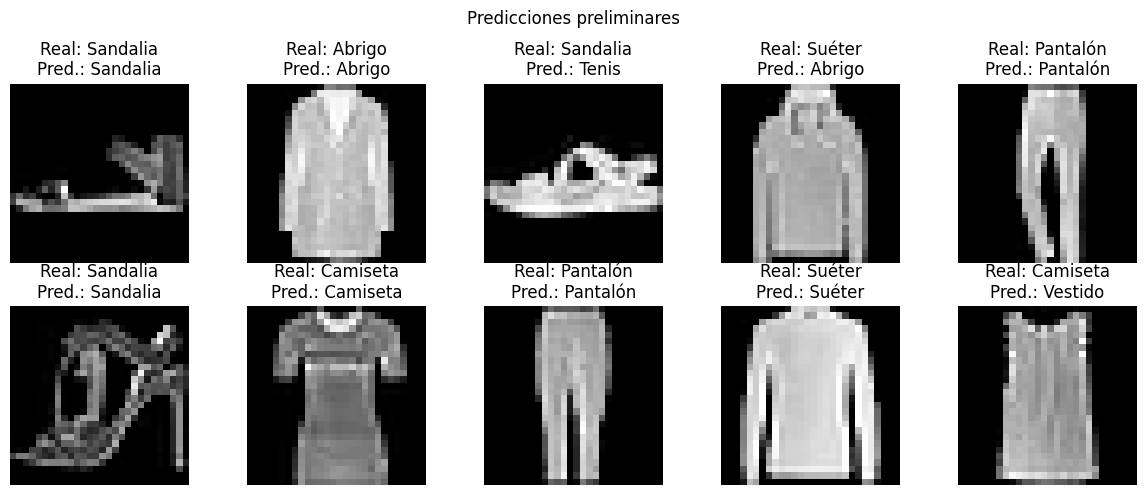


Calculando PCA...
Varianza explicada por PCA: 91.19%

Entrenando: Regresión logística con Píxeles crudos

Entrenando: Regresión logística con PCA (100 componentes)

Entrenando: SVM lineal con Píxeles crudos

Entrenando: SVM lineal con PCA (100 componentes)

Entrenando: Random Forest con Píxeles crudos

Entrenando: Random Forest con PCA (100 componentes)

TABLA COMPARATIVA PRELIMINAR


,modelo,representacion,tiempo_segundos,estado,accuracy,precision_ponderada,recall_ponderado,f1_ponderado,precision_macro,recall_macro,f1_macro
0,Random Forest,Píxeles crudos,102.826038,PRELIMINAR,0.884167,0.883595,0.884167,0.883142,0.883595,0.884167,0.883142
1,Random Forest,PCA (100 componentes),124.875133,PRELIMINAR,0.874167,0.873397,0.874167,0.872784,0.873397,0.874167,0.872784
2,Regresión logística,Píxeles crudos,53.224430,PRELIMINAR,0.856167,0.855454,0.856167,0.855683,0.855454,0.856167,0.855683
3,SVM lineal,Píxeles crudos,179.298203,PRELIMINAR,0.856083,0.854332,0.856083,0.854544,0.854332,0.856083,0.854544
4,Regresión logística,PCA (100 componentes),1.593225,PRELIMINAR,0.854333,0.853056,0.854333,0.853471,0.853056,0.854333,0.853471
5,SVM lineal,PCA (100 componentes),7.872132,PRELIMINAR,0.850667,0.848661,0.850667,0.848699,0.848661,0.850667,0.848699



Mejores representaciones:
{'Random Forest': 'Píxeles crudos', 'Regresión logística': 'Píxeles crudos', 'SVM lineal': 'Píxeles crudos'}

Ajustando: Regresión logística con Píxeles crudos
Fitting 3 folds for each of 3 candidates, totalling 9 fits

Ajustando: SVM lineal con Píxeles crudos
Fitting 3 folds for each of 3 candidates, totalling 9 fits

Ajustando: Random Forest con Píxeles crudos
Fitting 3 folds for each of 4 candidates, totalling 12 fits

Extrayendo HOG + Hu de entrenamiento...
Entrenamiento: 5000/48000
Entrenamiento: 10000/48000
Entrenamiento: 15000/48000
Entrenamiento: 20000/48000
Entrenamiento: 25000/48000
Entrenamiento: 30000/48000
Entrenamiento: 35000/48000
Entrenamiento: 40000/48000
Entrenamiento: 45000/48000

Extrayendo HOG + Hu de validación...
Validación: 5000/12000
Validación: 10000/12000

Ajustando regresión logística con HOG + Hu...
Fitting 3 folds for each of 4 candidates, totalling 12 fits

RESULTADOS DESPUÉS DE VALIDACIÓN CRUZADA


,candidato,modelo,representacion,mejores_parametros,f1_macro_cv,tiempo_ajuste_cv_segundos,accuracy,precision_ponderada,recall_ponderado,f1_ponderado,precision_macro,recall_macro,f1_macro
0,Regresión logística (HOG + Hu),Regresión logística,HOG + momentos de Hu,"{""modelo__C"": 0.01}",0.859910,38.227786,0.890083,0.889996,0.890083,0.890013,0.889996,0.890083,0.890013
1,Random Forest (Píxeles crudos),Random Forest,Píxeles crudos,"{""modelo__max_depth"": null, ""modelo__n_estimat...",0.853948,173.497618,0.884167,0.883595,0.884167,0.883142,0.883595,0.884167,0.883142
2,Regresión logística (Píxeles crudos),Regresión logística,Píxeles crudos,"{""modelo__C"": 0.1}",0.825068,52.564669,0.857667,0.856931,0.857667,0.857170,0.856931,0.857667,0.857170
3,SVM lineal (Píxeles crudos),SVM lineal,Píxeles crudos,"{""modelo__C"": 0.01}",0.817829,824.659941,0.857333,0.855448,0.857333,0.855644,0.855448,0.857333,0.855644



Extrayendo HOG + Hu de prueba...
Prueba: 5000/10000
Prueba: 10000/10000

Evaluando en prueba: Regresión logística (Píxeles crudos)


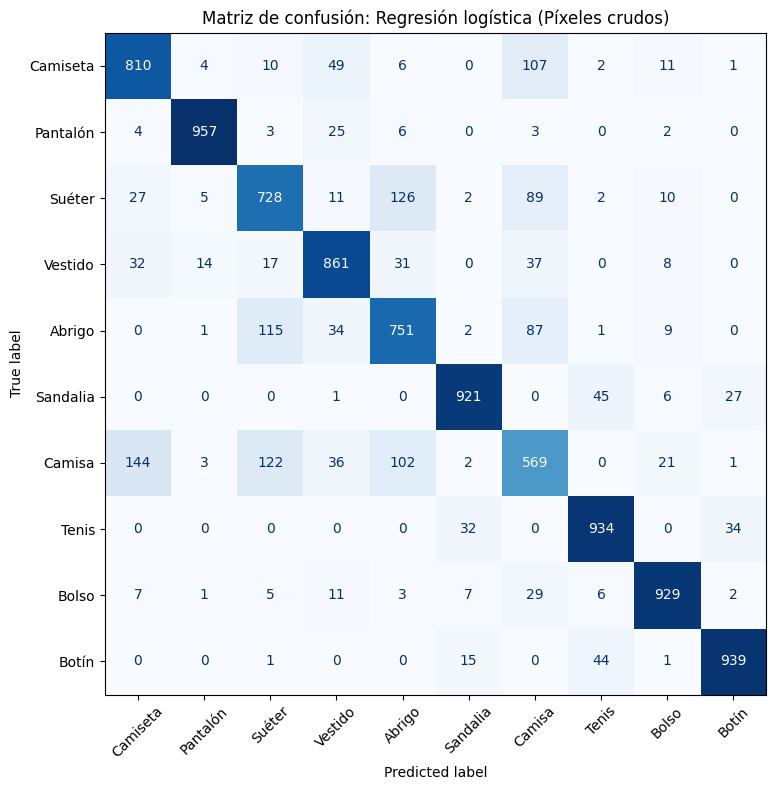


Evaluando en prueba: SVM lineal (Píxeles crudos)


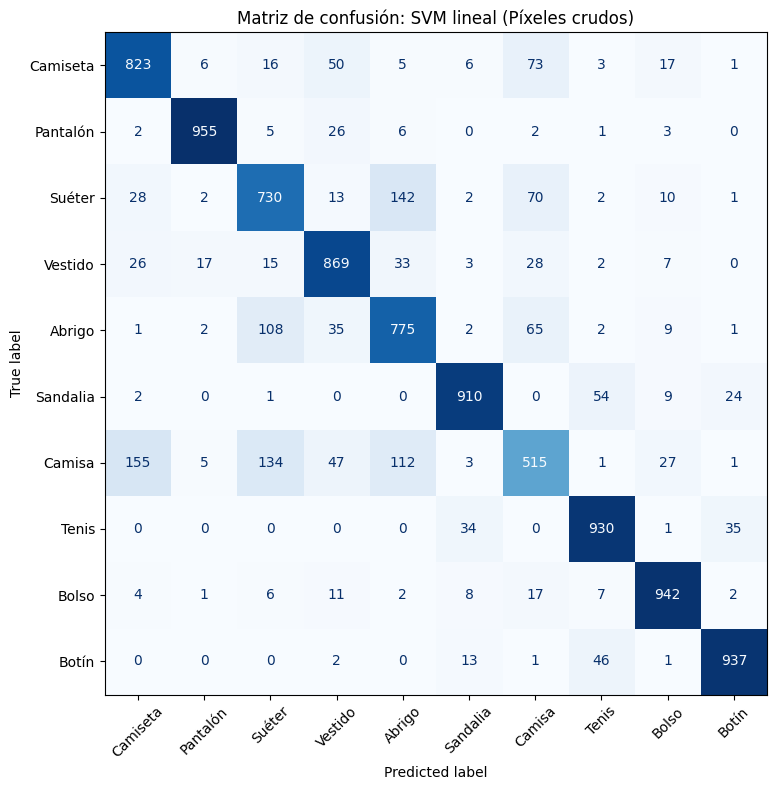


Evaluando en prueba: Random Forest (Píxeles crudos)


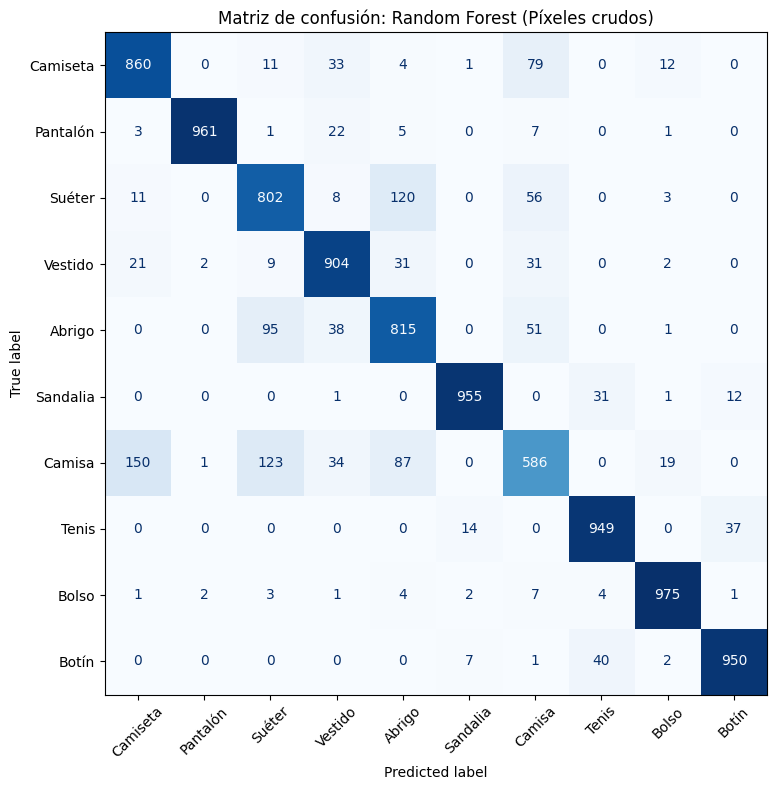


Evaluando en prueba: Regresión logística (HOG + Hu)


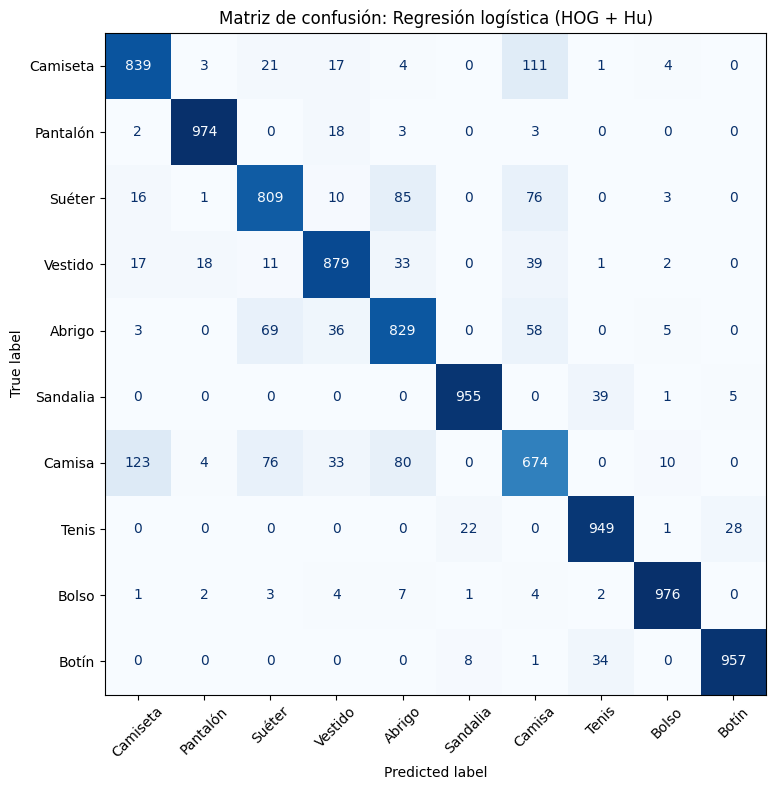


MÉTRICAS FINALES


,candidato,accuracy,precision_ponderada,recall_ponderado,f1_ponderado,precision_macro,recall_macro,f1_macro
0,Regresión logística (HOG + Hu),0.8841,0.883816,0.8841,0.883879,0.883816,0.8841,0.883879
1,Random Forest (Píxeles crudos),0.8757,0.874641,0.8757,0.874263,0.874641,0.8757,0.874263
2,Regresión logística (Píxeles crudos),0.8399,0.838708,0.8399,0.839125,0.838708,0.8399,0.839125
3,SVM lineal (Píxeles crudos),0.8386,0.835884,0.8386,0.835985,0.835884,0.8386,0.835985



Modelo elegido por F1 macro de validación: Regresión logística (HOG + Hu)
Cantidad de errores: 1159


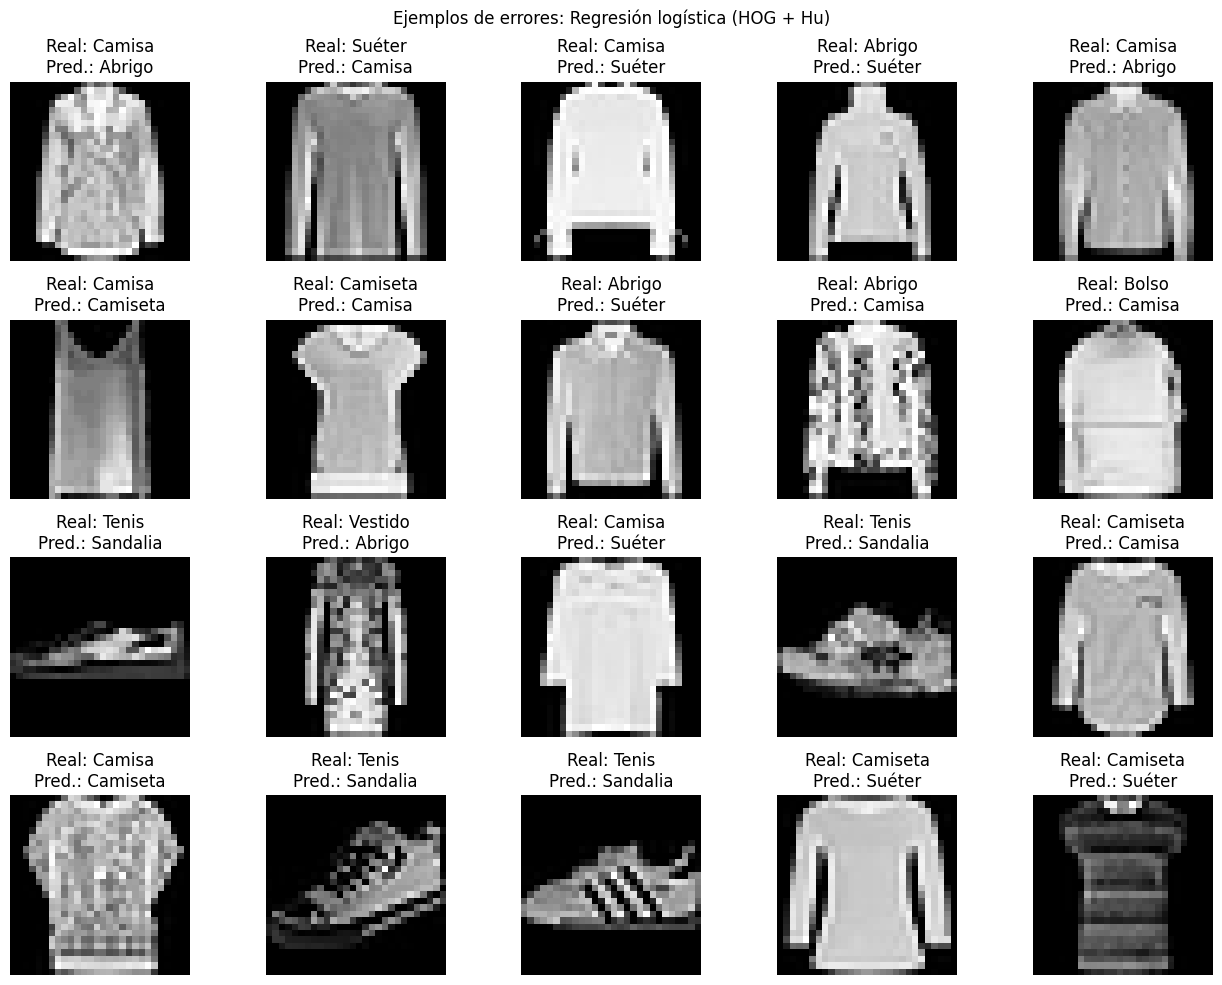


REPORTE DEL MODELO ELEGIDO
              precision    recall  f1-score   support

    Camiseta       0.84      0.84      0.84      1000
    Pantalón       0.97      0.97      0.97      1000
      Suéter       0.82      0.81      0.81      1000
     Vestido       0.88      0.88      0.88      1000
      Abrigo       0.80      0.83      0.81      1000
    Sandalia       0.97      0.95      0.96      1000
      Camisa       0.70      0.67      0.69      1000
       Tenis       0.92      0.95      0.94      1000
       Bolso       0.97      0.98      0.98      1000
       Botín       0.97      0.96      0.96      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000


TERMINADO
Carpeta: /content/StyleBot_modelos_resultados
ZIP: /content/StyleBot_modelos_resultados.zip
Modelo elegido: Regresión logística (HOG + Hu)


In [24]:
!pip -q install scikit-image

# ============================================================
# FASHION-MNIST: MODELOS, MÉTRICAS, FUENTES Y ENTREGABLES
# ============================================================

import time
import json
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

from skimage.feature import hog
from skimage.measure import moments_central, moments_normalized, moments_hu


# ------------------------------------------------------------
# CONFIGURACIÓN
# ------------------------------------------------------------

SEMILLA = 42
N_COMPONENTES_PCA = 100
TAMANO_CV = 12000

np.random.seed(SEMILLA)

assert "X_train" in globals(), "Primero ejecuta las celdas originales de datos."
assert X_train.shape[0] == 48000
assert X_val.shape[0] == 12000
assert X_test.shape[0] == 10000

if "CATEGORIAS" not in globals():
    CATEGORIAS = [
        "Camiseta", "Pantalón", "Suéter", "Vestido", "Abrigo",
        "Sandalia", "Camisa", "Tenis", "Bolso", "Botín"
    ]

CARPETA = Path("StyleBot_modelos_resultados")
(CARPETA / "matrices_confusion").mkdir(parents=True, exist_ok=True)
(CARPETA / "errores").mkdir(parents=True, exist_ok=True)

X_train_flat = X_train.reshape(len(X_train), -1)
X_val_flat = X_val.reshape(len(X_val), -1)
X_test_flat = X_test.reshape(len(X_test), -1)

print("Entrenamiento:", X_train_flat.shape)
print("Validación:", X_val_flat.shape)
print("Prueba:", X_test_flat.shape)


# ------------------------------------------------------------
# FUNCIONES
# ------------------------------------------------------------

def obtener_metricas(y_real, y_pred):
    p_weighted, r_weighted, f1_weighted, _ = precision_recall_fscore_support(
        y_real, y_pred, average="weighted", zero_division=0
    )

    p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(
        y_real, y_pred, average="macro", zero_division=0
    )

    return {
        "accuracy": accuracy_score(y_real, y_pred),
        "precision_ponderada": p_weighted,
        "recall_ponderado": r_weighted,
        "f1_ponderado": f1_weighted,
        "precision_macro": p_macro,
        "recall_macro": r_macro,
        "f1_macro": f1_macro,
    }


def crear_logistica(C=1.0):
    return LogisticRegression(
        C=C,
        solver="lbfgs",
        max_iter=2000,
        tol=1e-3,
        random_state=SEMILLA,
    )


def crear_svm(C=0.1):
    return LinearSVC(
        C=C,
        dual=False,
        tol=1e-3,
        max_iter=3000,
        random_state=SEMILLA,
    )


def crear_random_forest(n_estimators=150, max_depth=None):
    return RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        n_jobs=-1,
        random_state=SEMILLA,
    )


def crear_pipeline_base(nombre):
    if nombre == "Regresión logística":
        return Pipeline([
            ("escalador", StandardScaler()),
            ("modelo", crear_logistica()),
        ])

    if nombre == "SVM lineal":
        return Pipeline([
            ("escalador", StandardScaler()),
            ("modelo", crear_svm()),
        ])

    if nombre == "Random Forest":
        return Pipeline([
            ("modelo", crear_random_forest()),
        ])

    raise ValueError("Modelo no reconocido")


def crear_pipeline_ajuste(nombre, representacion):
    pasos = []

    if representacion == "PCA (100 componentes)":
        pasos.append((
            "pca",
            PCA(
                n_components=N_COMPONENTES_PCA,
                svd_solver="randomized",
                random_state=SEMILLA,
            ),
        ))

    if nombre == "Regresión logística":
        pasos.extend([
            ("escalador", StandardScaler()),
            ("modelo", crear_logistica()),
        ])

    elif nombre == "SVM lineal":
        pasos.extend([
            ("escalador", StandardScaler()),
            ("modelo", crear_svm()),
        ])

    elif nombre == "Random Forest":
        pasos.append(("modelo", crear_random_forest()))

    return Pipeline(pasos)


def extraer_hog_hu(imagenes, nombre):
    resultado = []

    for i, imagen in enumerate(imagenes):
        vector_hog = hog(
            imagen,
            orientations=9,
            pixels_per_cell=(4, 4),
            cells_per_block=(2, 2),
            block_norm="L2-Hys",
        )

        mu = moments_central(imagen)
        nu = moments_normalized(mu)
        hu = moments_hu(nu)

        # La escala logarítmica hace estables los valores de Hu.
        hu = np.sign(hu) * np.log1p(np.abs(hu))

        resultado.append(np.concatenate([vector_hog, hu]))

        if (i + 1) % 5000 == 0:
            print(f"{nombre}: {i + 1}/{len(imagenes)}")

    return np.asarray(resultado, dtype=np.float32)


# ------------------------------------------------------------
# 1. CLASIFICADOR PRELIMINAR
# ------------------------------------------------------------

idx_pequena, _ = train_test_split(
    np.arange(len(y_train)),
    train_size=5000,
    stratify=y_train,
    random_state=SEMILLA,
)

modelo_preliminar = Pipeline([
    ("escalador", StandardScaler()),
    ("modelo", crear_logistica()),
])

inicio = time.perf_counter()
modelo_preliminar.fit(X_train_flat[idx_pequena], y_train[idx_pequena])
tiempo_preliminar = time.perf_counter() - inicio

pred_preliminar = modelo_preliminar.predict(X_val_flat)
metricas_preliminares = obtener_metricas(y_val, pred_preliminar)

tabla_preliminar = pd.DataFrame([{
    "modelo": "Regresión logística",
    "representacion": "Píxeles crudos",
    "muestra_entrenamiento": 5000,
    "tiempo_segundos": tiempo_preliminar,
    "estado": "PRELIMINAR",
    **metricas_preliminares,
}])

print("\nRESULTADO PRELIMINAR")
display(tabla_preliminar)

tabla_preliminar.to_csv(
    CARPETA / "tabla_preliminar.csv",
    index=False,
    encoding="utf-8-sig",
)

fig, ejes = plt.subplots(2, 5, figsize=(12, 5))

for eje, indice in zip(ejes.ravel(), range(10)):
    eje.imshow(X_val[indice], cmap="gray")
    eje.set_title(
        f"Real: {CATEGORIAS[y_val[indice]]}\n"
        f"Pred.: {CATEGORIAS[pred_preliminar[indice]]}"
    )
    eje.axis("off")

fig.suptitle("Predicciones preliminares")
fig.tight_layout()
fig.savefig(CARPETA / "predicciones_preliminares.png", dpi=160)
plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 2. PCA
# ------------------------------------------------------------

print("\nCalculando PCA...")

pca_base = PCA(
    n_components=N_COMPONENTES_PCA,
    svd_solver="randomized",
    random_state=SEMILLA,
)

X_train_pca = pca_base.fit_transform(X_train_flat)
X_val_pca = pca_base.transform(X_val_flat)

print(
    f"Varianza explicada por PCA: "
    f"{pca_base.explained_variance_ratio_.sum():.2%}"
)


# ------------------------------------------------------------
# 3. MODELOS BASE: PÍXELES CRUDOS Y PCA
# ------------------------------------------------------------

representaciones = {
    "Píxeles crudos": (X_train_flat, X_val_flat),
    "PCA (100 componentes)": (X_train_pca, X_val_pca),
}

nombres_modelos = [
    "Regresión logística",
    "SVM lineal",
    "Random Forest",
]

filas_base = []

for nombre_modelo in nombres_modelos:
    for nombre_representacion, (X_entrena, X_valida) in representaciones.items():
        print(f"\nEntrenando: {nombre_modelo} con {nombre_representacion}")

        modelo = crear_pipeline_base(nombre_modelo)

        inicio = time.perf_counter()
        modelo.fit(X_entrena, y_train)
        segundos = time.perf_counter() - inicio

        pred = modelo.predict(X_valida)
        metricas = obtener_metricas(y_val, pred)

        filas_base.append({
            "modelo": nombre_modelo,
            "representacion": nombre_representacion,
            "tiempo_segundos": segundos,
            "estado": "PRELIMINAR",
            **metricas,
        })

tabla_base = pd.DataFrame(filas_base).sort_values(
    "f1_macro",
    ascending=False,
).reset_index(drop=True)

print("\nTABLA COMPARATIVA PRELIMINAR")
display(tabla_base)

tabla_base.to_csv(
    CARPETA / "tabla_comparativa_preliminar.csv",
    index=False,
    encoding="utf-8-sig",
)

mejores_representaciones = (
    tabla_base.loc[
        tabla_base.groupby("modelo")["f1_macro"].idxmax(),
        ["modelo", "representacion"],
    ]
    .set_index("modelo")["representacion"]
    .to_dict()
)

print("\nMejores representaciones:")
print(mejores_representaciones)


# ------------------------------------------------------------
# 4. VALIDACIÓN CRUZADA Y AJUSTE
# ------------------------------------------------------------

idx_cv, _ = train_test_split(
    np.arange(len(y_train)),
    train_size=TAMANO_CV,
    stratify=y_train,
    random_state=SEMILLA,
)

X_cv = X_train_flat[idx_cv]
y_cv = y_train[idx_cv]

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEMILLA,
)

parametros_por_modelo = {
    "Regresión logística": {
        "modelo__C": [0.1, 1.0, 10.0],
    },
    "SVM lineal": {
        "modelo__C": [0.01, 0.1, 1.0],
    },
    "Random Forest": {
        "modelo__n_estimators": [100, 150],
        "modelo__max_depth": [None, 25],
    },
}

modelos_ajustados = {}
filas_ajuste = []

for nombre_modelo in nombres_modelos:
    representacion = mejores_representaciones[nombre_modelo]

    print(f"\nAjustando: {nombre_modelo} con {representacion}")

    busqueda = GridSearchCV(
        estimator=crear_pipeline_ajuste(nombre_modelo, representacion),
        param_grid=parametros_por_modelo[nombre_modelo],
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
        refit=True,
        verbose=1,
    )

    inicio = time.perf_counter()
    busqueda.fit(X_cv, y_cv)
    segundos_cv = time.perf_counter() - inicio

    modelo_final_familia = clone(busqueda.best_estimator_)
    modelo_final_familia.fit(X_train_flat, y_train)

    pred_val = modelo_final_familia.predict(X_val_flat)
    metricas = obtener_metricas(y_val, pred_val)

    candidato = f"{nombre_modelo} ({representacion})"
    modelos_ajustados[candidato] = modelo_final_familia

    filas_ajuste.append({
        "candidato": candidato,
        "modelo": nombre_modelo,
        "representacion": representacion,
        "mejores_parametros": json.dumps(busqueda.best_params_),
        "f1_macro_cv": busqueda.best_score_,
        "tiempo_ajuste_cv_segundos": segundos_cv,
        **metricas,
    })


# ------------------------------------------------------------
# 5. LOGÍSTICA CON HOG + MOMENTOS DE HU
# ------------------------------------------------------------

print("\nExtrayendo HOG + Hu de entrenamiento...")
X_train_hog_hu = extraer_hog_hu(X_train, "Entrenamiento")

print("\nExtrayendo HOG + Hu de validación...")
X_val_hog_hu = extraer_hog_hu(X_val, "Validación")

pipeline_hog_hu = Pipeline([
    ("escalador", StandardScaler()),
    ("modelo", crear_logistica()),
])

busqueda_hog_hu = GridSearchCV(
    estimator=pipeline_hog_hu,
    param_grid={"modelo__C": [0.01, 0.1, 1.0, 10.0]},
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1,
)

print("\nAjustando regresión logística con HOG + Hu...")

inicio = time.perf_counter()
busqueda_hog_hu.fit(X_train_hog_hu[idx_cv], y_train[idx_cv])
segundos_hog_hu = time.perf_counter() - inicio

modelo_hog_hu = clone(busqueda_hog_hu.best_estimator_)
modelo_hog_hu.fit(X_train_hog_hu, y_train)

pred_val_hog_hu = modelo_hog_hu.predict(X_val_hog_hu)
metricas_hog_hu = obtener_metricas(y_val, pred_val_hog_hu)

nombre_hog_hu = "Regresión logística (HOG + Hu)"
modelos_ajustados[nombre_hog_hu] = modelo_hog_hu

filas_ajuste.append({
    "candidato": nombre_hog_hu,
    "modelo": "Regresión logística",
    "representacion": "HOG + momentos de Hu",
    "mejores_parametros": json.dumps(busqueda_hog_hu.best_params_),
    "f1_macro_cv": busqueda_hog_hu.best_score_,
    "tiempo_ajuste_cv_segundos": segundos_hog_hu,
    **metricas_hog_hu,
})

tabla_ajuste = pd.DataFrame(filas_ajuste).sort_values(
    "f1_macro",
    ascending=False,
).reset_index(drop=True)

print("\nRESULTADOS DESPUÉS DE VALIDACIÓN CRUZADA")
display(tabla_ajuste)

tabla_ajuste.to_csv(
    CARPETA / "tabla_ajuste_validacion_cruzada.csv",
    index=False,
    encoding="utf-8-sig",
)


# ------------------------------------------------------------
# 6. PRUEBA FINAL, MÉTRICAS MACRO Y MATRICES
# ------------------------------------------------------------

print("\nExtrayendo HOG + Hu de prueba...")
X_test_hog_hu = extraer_hog_hu(X_test, "Prueba")

filas_finales = []
predicciones_finales = {}

for candidato, modelo in modelos_ajustados.items():
    print(f"\nEvaluando en prueba: {candidato}")

    X_entrada = X_test_hog_hu if candidato == nombre_hog_hu else X_test_flat
    pred_prueba = modelo.predict(X_entrada)

    predicciones_finales[candidato] = pred_prueba
    metricas = obtener_metricas(y_test, pred_prueba)

    filas_finales.append({
        "candidato": candidato,
        **metricas,
    })

    matriz = confusion_matrix(y_test, pred_prueba)

    fig, eje = plt.subplots(figsize=(10, 8))
    ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=CATEGORIAS,
    ).plot(
        ax=eje,
        cmap="Blues",
        xticks_rotation=45,
        colorbar=False,
    )

    eje.set_title(f"Matriz de confusión: {candidato}")
    fig.tight_layout()

    archivo = (
        candidato
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
        .replace("+", "mas")
    )

    fig.savefig(
        CARPETA / "matrices_confusion" / f"{archivo}.png",
        dpi=180,
    )

    plt.show()
    plt.close(fig)

tabla_final = pd.DataFrame(filas_finales).sort_values(
    "f1_macro",
    ascending=False,
).reset_index(drop=True)

print("\nMÉTRICAS FINALES")
display(tabla_final)

tabla_final.to_csv(
    CARPETA / "metricas_finales_prueba.csv",
    index=False,
    encoding="utf-8-sig",
)


# ------------------------------------------------------------
# 7. ERRORES DEL MODELO SELECCIONADO
# ------------------------------------------------------------

modelo_elegido = tabla_ajuste.iloc[0]["candidato"]
pred_elegido = predicciones_finales[modelo_elegido]

errores = np.flatnonzero(pred_elegido != y_test)

print(f"\nModelo elegido por F1 macro de validación: {modelo_elegido}")
print(f"Cantidad de errores: {len(errores)}")

rng = np.random.default_rng(SEMILLA)
muestra_errores = rng.choice(
    errores,
    size=min(20, len(errores)),
    replace=False,
)

fig, ejes = plt.subplots(4, 5, figsize=(13, 10))

for eje, indice in zip(ejes.ravel(), muestra_errores):
    eje.imshow(X_test[indice], cmap="gray")
    eje.set_title(
        f"Real: {CATEGORIAS[y_test[indice]]}\n"
        f"Pred.: {CATEGORIAS[pred_elegido[indice]]}"
    )
    eje.axis("off")

fig.suptitle(f"Ejemplos de errores: {modelo_elegido}")
fig.tight_layout()
fig.savefig(
    CARPETA / "errores" / "ejemplos_de_errores.png",
    dpi=180,
)

plt.show()
plt.close(fig)

reporte = classification_report(
    y_test,
    pred_elegido,
    target_names=CATEGORIAS,
    zero_division=0,
)

print("\nREPORTE DEL MODELO ELEGIDO")
print(reporte)

(CARPETA / "reporte_clasificacion_modelo_elegido.txt").write_text(
    reporte,
    encoding="utf-8",
)


# ------------------------------------------------------------
# 8. README CON FUENTES Y EXPLICACIÓN DE CONVERGENCIA
# ------------------------------------------------------------

mejor_fila = tabla_final.iloc[0]

readme = f"""# Resultados de Fashion-MNIST

## Responsable
Ángel Uriel Martínez Godínez

## División de datos
- Entrenamiento: 48,000 imágenes.
- Validación: 12,000 imágenes.
- Prueba final: 10,000 imágenes.
- Semilla: {SEMILLA}.

## Modelos comparados
- Regresión logística.
- SVM lineal.
- Random Forest.
- Regresión logística con HOG y momentos de Hu.
- Píxeles crudos y PCA.

## Modelo elegido por validación
{modelo_elegido}

## Mejor resultado de prueba
- Candidato: {mejor_fila["candidato"]}
- Accuracy: {mejor_fila["accuracy"]:.4f}
- Precision ponderada: {mejor_fila["precision_ponderada"]:.4f}
- Recall ponderado: {mejor_fila["recall_ponderado"]:.4f}
- F1 ponderado: {mejor_fila["f1_ponderado"]:.4f}
- Precision macro: {mejor_fila["precision_macro"]:.4f}
- Recall macro: {mejor_fila["recall_macro"]:.4f}
- F1 macro: {mejor_fila["f1_macro"]:.4f}

## Convergencia
Las características de los modelos lineales se estandarizaron con
`StandardScaler`. También se configuró la regresión logística con
`max_iter=2000` y `tol=0.001`; esto da más iteraciones al optimizador
y reduce las advertencias de convergencia.

## Fuentes específicas
- Fashion-MNIST:
  https://www.tensorflow.org/api_docs/python/tf/keras/datasets/fashion_mnist/load_data
- LogisticRegression:
  https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
- LinearSVC:
  https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html
- RandomForestClassifier:
  https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
- PCA:
  https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html
- GridSearchCV:
  https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
- Métricas:
  https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_fscore_support.html
- HOG:
  https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.hog
- Momentos de Hu:
  https://scikit-image.org/docs/stable/api/skimage.measure.html#skimage.measure.moments_hu
"""

(CARPETA / "README_resultados.md").write_text(
    readme,
    encoding="utf-8",
)

shutil.make_archive(
    "StyleBot_modelos_resultados",
    "zip",
    root_dir=CARPETA,
)

print("\n" + "=" * 60)
print("TERMINADO")
print("Carpeta:", CARPETA.resolve())
print("ZIP:", Path("StyleBot_modelos_resultados.zip").resolve())
print("Modelo elegido:", modelo_elegido)
print("=" * 60)

# **5. Aprendizaje no supervisado**

    Agrupamiento y exploración de prendas similares.

    - Responsable: Luis Ángel Mendosa Gaytan
    - Estado: Completo
    - Archivo del que proviene el trabajo: 05_aprendizaje_no_supervisado.ipynb

**Funciones de agrupamiento y recomendación:**

    Las mismas funciones están en `src/recomendador_stylebot.py` para la integración.

    -`ajustar_pca`: PCA ajustado solo con entrenamiento.
    -`ajustar_kmeans` y `metricas_agrupamiento`: K-Means y su comparación contra las categorías reales (pureza, ARI y NMI).
    -`construir_recomendador` y `recomendar`: búsqueda de las prendas más cercanas en el catálogo.
    -`recomendar_mismo_grupo`: variante que busca solo dentro del mismo grupo de K-Means.
    -`recomendaciones_aleatorias` y `precision_en_k`: línea base y métrica.

In [ ]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.neighbors import NearestNeighbors

SEMILLA = 42


def a_vectores(X):
    """(n, 28, 28) -> (n, 784). No vuelve a normalizar: los píxeles ya están entre 0 y 1."""
    return X.reshape(len(X), -1)


def ajustar_pca(X_train, n_componentes=50, semilla=SEMILLA):
    """Ajusta PCA solo con entrenamiento. Validación y prueba únicamente se transforman."""
    pca = PCA(n_components=n_componentes, random_state=semilla)
    pca.fit(a_vectores(X_train))
    return pca


def ajustar_kmeans(Z_train, k=10, semilla=SEMILLA, n_init=10):
    """K-Means sobre las características de entrenamiento."""
    modelo = KMeans(n_clusters=k, n_init=n_init, random_state=semilla)
    modelo.fit(Z_train)
    return modelo


def tabla_contingencia(grupos, y, k=10, n_categorias=10):
    """Filas = grupos de K-Means, columnas = categorías reales."""
    tabla = np.zeros((k, n_categorias), dtype=np.int64)
    np.add.at(tabla, (grupos, y), 1)
    return tabla


def metricas_agrupamiento(grupos, y, k=10):
    """Pureza, ARI y NMI. Las etiquetas solo se usan para evaluar, no para agrupar."""
    tabla = tabla_contingencia(grupos, y, k)
    return {
        "pureza": float(tabla.max(axis=1).sum() / tabla.sum()),
        "ari": float(adjusted_rand_score(y, grupos)),
        "nmi": float(normalized_mutual_info_score(y, grupos)),
    }


def construir_recomendador(Z_catalogo, metrica="cosine"):
    """Índice de vecinos más cercanos sobre el catálogo (entrenamiento)."""
    return NearestNeighbors(metric=metrica, algorithm="brute").fit(Z_catalogo)


def recomendar(indice, Z_consultas, k=5):
    """Devuelve, para cada consulta, las posiciones de las k prendas más parecidas del catálogo."""
    _, posiciones = indice.kneighbors(Z_consultas, n_neighbors=k)
    return posiciones


def recomendar_mismo_grupo(Z_catalogo, grupos_catalogo, Z_consultas, grupos_consultas,
                           k=5, metrica="cosine"):
    """Variante: busca vecinos solo entre las prendas del mismo grupo de K-Means."""
    posiciones = np.empty((len(Z_consultas), k), dtype=np.int64)
    for g in np.unique(grupos_consultas):
        en_grupo = np.flatnonzero(grupos_catalogo == g)
        consultas = np.flatnonzero(grupos_consultas == g)
        indice = construir_recomendador(Z_catalogo[en_grupo], metrica)
        _, locales = indice.kneighbors(Z_consultas[consultas], n_neighbors=k)
        posiciones[consultas] = en_grupo[locales]
    return posiciones


def recomendaciones_aleatorias(n_consultas, n_catalogo, k=5, semilla=SEMILLA):
    """Línea base: k prendas del catálogo elegidas al azar, sin repetir dentro de cada consulta."""
    rng = np.random.default_rng(semilla)
    return np.stack([rng.choice(n_catalogo, size=k, replace=False) for _ in range(n_consultas)])


def aciertos(y_consultas, y_catalogo, posiciones):
    """Matriz booleana: True si la recomendación es de la misma categoría que la consulta."""
    return y_catalogo[posiciones] == y_consultas[:, None]


def precision_en_k(y_consultas, y_catalogo, posiciones):
    """Precision@k promedio: fracción de recomendaciones de la misma categoría."""
    return float(aciertos(y_consultas, y_catalogo, posiciones).mean())

# Carpeta de resultados de esta parte
from pathlib import Path
import csv

CARPETA_NO_SUPERVISADO = Path("StyleBot_agrupamiento_generado")
for subcarpeta in ["resultados/tablas", "resultados/graficas"]:
    (CARPETA_NO_SUPERVISADO / subcarpeta).mkdir(parents=True, exist_ok=True)

def guardar_tabla_ns(nombre, filas):
    ruta = CARPETA_NO_SUPERVISADO / "resultados/tablas" / nombre
    with ruta.open("w", newline="", encoding="utf-8-sig") as archivo:
        escritor = csv.DictWriter(archivo, fieldnames=list(filas[0].keys()))
        escritor.writeheader()
        escritor.writerows(filas)

def guardar_figura_ns(fig, nombre):
    fig.savefig(CARPETA_NO_SUPERVISADO / "resultados/graficas" / nombre, dpi=150, bbox_inches="tight")

**Características: PCA de 50 componentes**

    Misma configuración que `02_caracteristicas.ipynb`: 784 píxeles reducidos a 50 componentes, ajustando solo con entrenamiento.

In [ ]:
# PCA propio de esta sección. No se reutiliza X_train_pca porque en la sección 4
# (aprendizaje clásico) ese nombre se reescribe con 100 componentes.
import time
from sklearn.decomposition import PCA

X_train_flat_ns = X_train.reshape(len(X_train), -1)
pca = PCA(n_components=50, random_state=SEMILLA).fit(X_train_flat_ns)
Z_train = pca.transform(X_train_flat_ns)
Z_val = pca.transform(X_val.reshape(len(X_val), -1))
Z_test = pca.transform(X_test.reshape(len(X_test), -1))
print("PCA 50 componentes, varianza conservada:", f"{pca.explained_variance_ratio_.sum():.2%}")
print("Características:", Z_train.shape, Z_val.shape, Z_test.shape)

PCA 50 componentes, varianza conservada: 86.27%
Características: (48000, 50) (12000, 50) (10000, 50)


**Agrupamiento con K-Means**

    Ejemplo pequeño:

    Primera prueba rápida de K-Means: 2,000 imágenes de entrenamiento elegidas al azar y 10 grupos. Sirve para confirmar
    que el procedimiento funciona antes de usar las 48,000 imágenes. Se muestran seis imágenes de cuatro grupos; K-Means
    no recibe las etiquetas.

Imágenes por grupo: [253, 198, 193, 322, 211, 157, 240, 256, 94, 76]


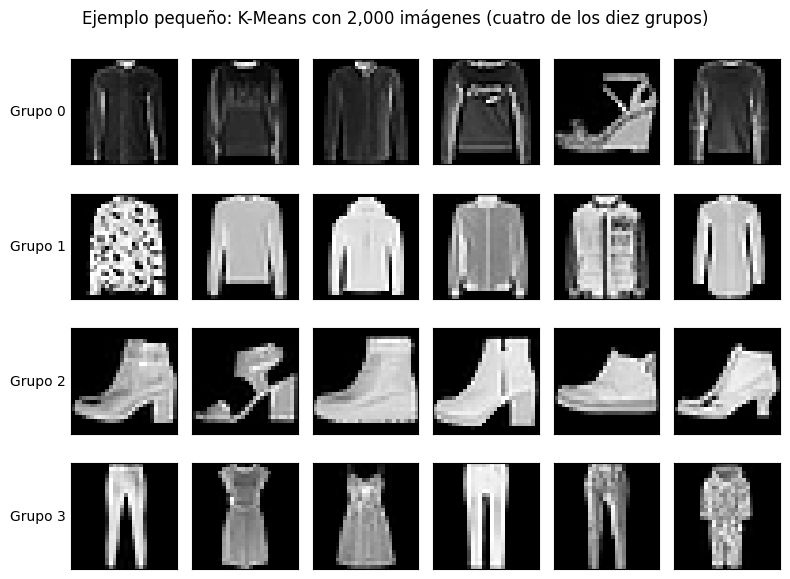

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(SEMILLA)
muestra_pequena = rng.choice(len(Z_train), size=2000, replace=False)
kmeans_pequeno = ajustar_kmeans(Z_train[muestra_pequena], k=10, n_init=10)
grupos_pequenos = kmeans_pequeno.labels_
print("Imágenes por grupo:", np.bincount(grupos_pequenos, minlength=10).tolist())

fig, ejes = plt.subplots(4, 6, figsize=(8, 6))
for fila, g in enumerate(range(4)):
    elegidas = rng.choice(np.flatnonzero(grupos_pequenos == g), size=6, replace=False)
    for j, posicion in enumerate(elegidas):
        ejes[fila, j].imshow(X_train[muestra_pequena[posicion]], cmap="gray", vmin=0, vmax=1)
        ejes[fila, j].set_xticks([]); ejes[fila, j].set_yticks([])
    ejes[fila, 0].set_ylabel(f"Grupo {g}", rotation=0, ha="right", va="center")
fig.suptitle("Ejemplo pequeño: K-Means con 2,000 imágenes (cuatro de los diez grupos)")
fig.tight_layout()
guardar_figura_ns(fig, "kmeans_ejemplo_pequeno.png")
plt.show(); plt.close(fig)

**Revisar varios números de grupos:**

    Usamos 10 grupos porque el dataset tiene 10 categorías, pero antes revisamos cómo cambian la inercia y la silueta
    con otros valores. La silueta se calcula con una muestra de 5,000 imágenes de entrenamiento para que sea rápida.
    Esta revisión es solo de contexto: no usa las etiquetas.

k= 4  inercia=   1554618.1  silueta=0.2222
k= 6  inercia=   1313209.1  silueta=0.2029
k= 8  inercia=   1175054.0  silueta=0.2197
k=10  inercia=   1086460.4  silueta=0.1786
k=12  inercia=   1000052.0  silueta=0.1850
k=14  inercia=    941227.6  silueta=0.1779


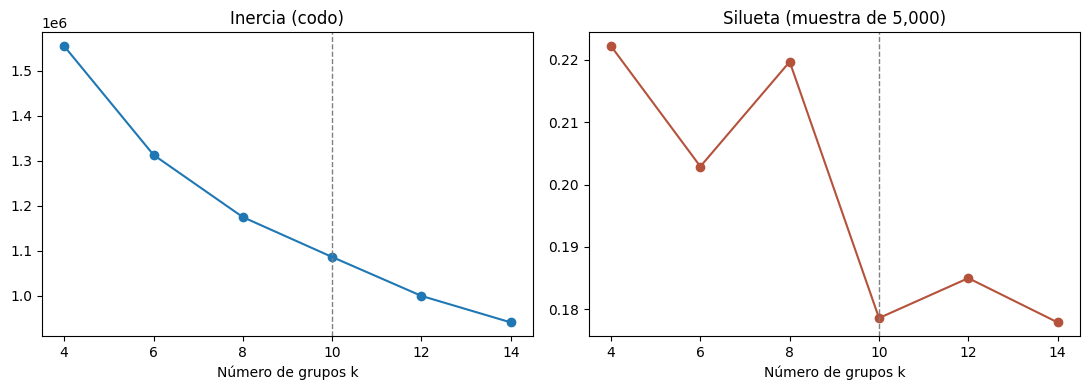

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score

rng = np.random.default_rng(SEMILLA)
muestra_sil = rng.choice(len(Z_train), size=5000, replace=False)

valores_k = [4, 6, 8, 10, 12, 14]
revision_k = []
for k in valores_k:
    modelo_k = ajustar_kmeans(Z_train, k=k, n_init=3)
    sil = silhouette_score(Z_train[muestra_sil], modelo_k.labels_[muestra_sil])
    revision_k.append({"k": k, "inercia": round(float(modelo_k.inertia_), 1), "silueta_muestra": round(float(sil), 4)})
    print(f"k={k:2}  inercia={modelo_k.inertia_:12.1f}  silueta={sil:.4f}")
guardar_tabla_ns("kmeans_revision_k.csv", revision_k)

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
ejes[0].plot(valores_k, [f["inercia"] for f in revision_k], marker="o")
ejes[0].set_title("Inercia (codo)"); ejes[0].set_xlabel("Número de grupos k")
ejes[1].plot(valores_k, [f["silueta_muestra"] for f in revision_k], marker="o", color="#b5523b")
ejes[1].set_title("Silueta (muestra de 5,000)"); ejes[1].set_xlabel("Número de grupos k")
for eje in ejes:
    eje.axvline(10, color="gray", linestyle="--", linewidth=1)
fig.tight_layout()
guardar_figura_ns(fig, "kmeans_revision_k.png")
plt.show(); plt.close(fig)

**K-Means con 10 grupos:**

    K-Means no conoce las categorías. Después de agrupar, comparamos los grupos con las categorías reales:

    -Pureza: porcentaje de imágenes que pertenecen a la categoría mayoritaria de su grupo.
    -ARI (índice de Rand ajustado): 0 equivale a agrupar al azar y 1 a coincidir perfectamente con las categorías.
    -NMI (información mutua normalizada): de 0 a 1, cuánto informan los grupos sobre la categoría.

    Validación se asigna a grupos con `predict`, sin volver a ajustar.

K-Means ajustado en 3.0 s
entrenamiento  pureza=0.552  ARI=0.347  NMI=0.511
validacion     pureza=0.558  ARI=0.347  NMI=0.512

Grupo | Imágenes | Categoría mayoritaria | % | Segunda categoría | %
    0 |     7264 | Pantalón              |  59.6 | Vestido           |  35.5
    1 |     5236 | Tenis                 |  71.4 | Sandalia          |  21.9
    2 |     2076 | Bolso                 |  94.9 | Camiseta          |   1.3
    3 |     6226 | Sandalia              |  48.4 | Camisa            |   9.9
    4 |     7710 | Abrigo                |  37.2 | Suéter            |  37.0
    5 |     5933 | Camisa                |  27.7 | Suéter            |  23.6
    6 |     2339 | Botín                 |  90.3 | Sandalia          |   8.7
    7 |     5881 | Camiseta              |  45.9 | Vestido           |  23.0
    8 |     3447 | Botín                 |  68.6 | Tenis             |  18.1
    9 |     1888 | Bolso                 |  93.6 | Camisa            |   2.9


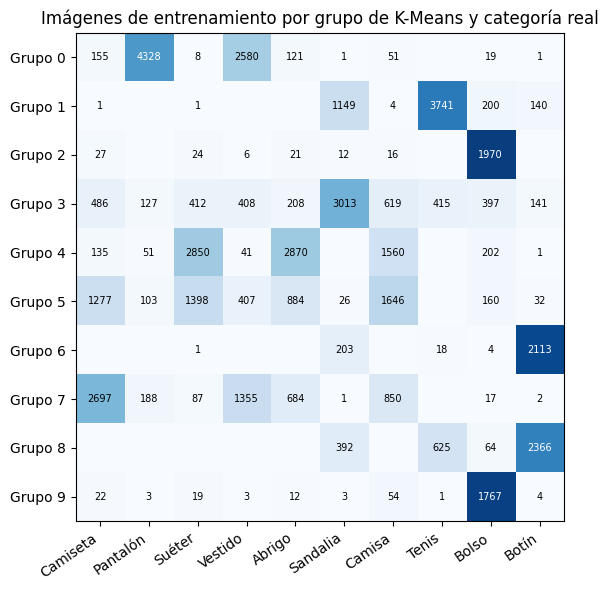

In [ ]:
inicio = time.time()
kmeans = ajustar_kmeans(Z_train, k=10, n_init=10)
grupos_train = kmeans.labels_
grupos_val = kmeans.predict(Z_val)
print(f"K-Means ajustado en {time.time() - inicio:.1f} s")

filas_metricas = []
for nombre, grupos, y in [("entrenamiento", grupos_train, y_train), ("validacion", grupos_val, y_val)]:
    m = metricas_agrupamiento(grupos, y)
    filas_metricas.append({"conjunto": nombre, **{c: round(v, 4) for c, v in m.items()}})
    print(f"{nombre:14} pureza={m['pureza']:.3f}  ARI={m['ari']:.3f}  NMI={m['nmi']:.3f}")
guardar_tabla_ns("kmeans_metricas.csv", filas_metricas)

tabla = tabla_contingencia(grupos_train, y_train)
resumen_grupos = []
print("\nGrupo | Imágenes | Categoría mayoritaria | % | Segunda categoría | %")
for g in range(10):
    orden = np.argsort(tabla[g])[::-1]
    total = int(tabla[g].sum())
    fila = {
        "grupo": g, "imagenes": total,
        "categoria_mayoritaria": CATEGORIAS[orden[0]], "porcentaje_mayoritaria": round(100 * tabla[g, orden[0]] / total, 1),
        "segunda_categoria": CATEGORIAS[orden[1]], "porcentaje_segunda": round(100 * tabla[g, orden[1]] / total, 1),
    }
    resumen_grupos.append(fila)
    print(f"{g:5} | {total:8} | {fila['categoria_mayoritaria']:21} | {fila['porcentaje_mayoritaria']:5} | "
          f"{fila['segunda_categoria']:17} | {fila['porcentaje_segunda']:5}")
guardar_tabla_ns("kmeans_resumen_grupos.csv", resumen_grupos)
guardar_tabla_ns("kmeans_contingencia_entrenamiento.csv",
            [{"grupo": g, **{CATEGORIAS[c]: int(tabla[g, c]) for c in range(10)}} for g in range(10)])

fig, ax = plt.subplots(figsize=(10, 6))
proporcion = tabla / tabla.sum(axis=1, keepdims=True)
ax.imshow(proporcion, cmap="Blues", vmin=0, vmax=1)
for g in range(10):
    for c in range(10):
        if tabla[g, c] > 0:
            ax.text(c, g, tabla[g, c], ha="center", va="center", fontsize=7,
                    color="white" if proporcion[g, c] > 0.5 else "black")
ax.set_xticks(range(10), CATEGORIAS, rotation=35, ha="right")
ax.set_yticks(range(10), [f"Grupo {g}" for g in range(10)])
ax.set_title("Imágenes de entrenamiento por grupo de K-Means y categoría real")
fig.tight_layout()
guardar_figura_ns(fig, "kmeans_contingencia.png")
plt.show(); plt.close(fig)

**Ejemplos de cada grupo:**

    Ocho imágenes de entrenamiento elegidas al azar dentro de cada grupo. El título indica la categoría mayoritaria del grupo.

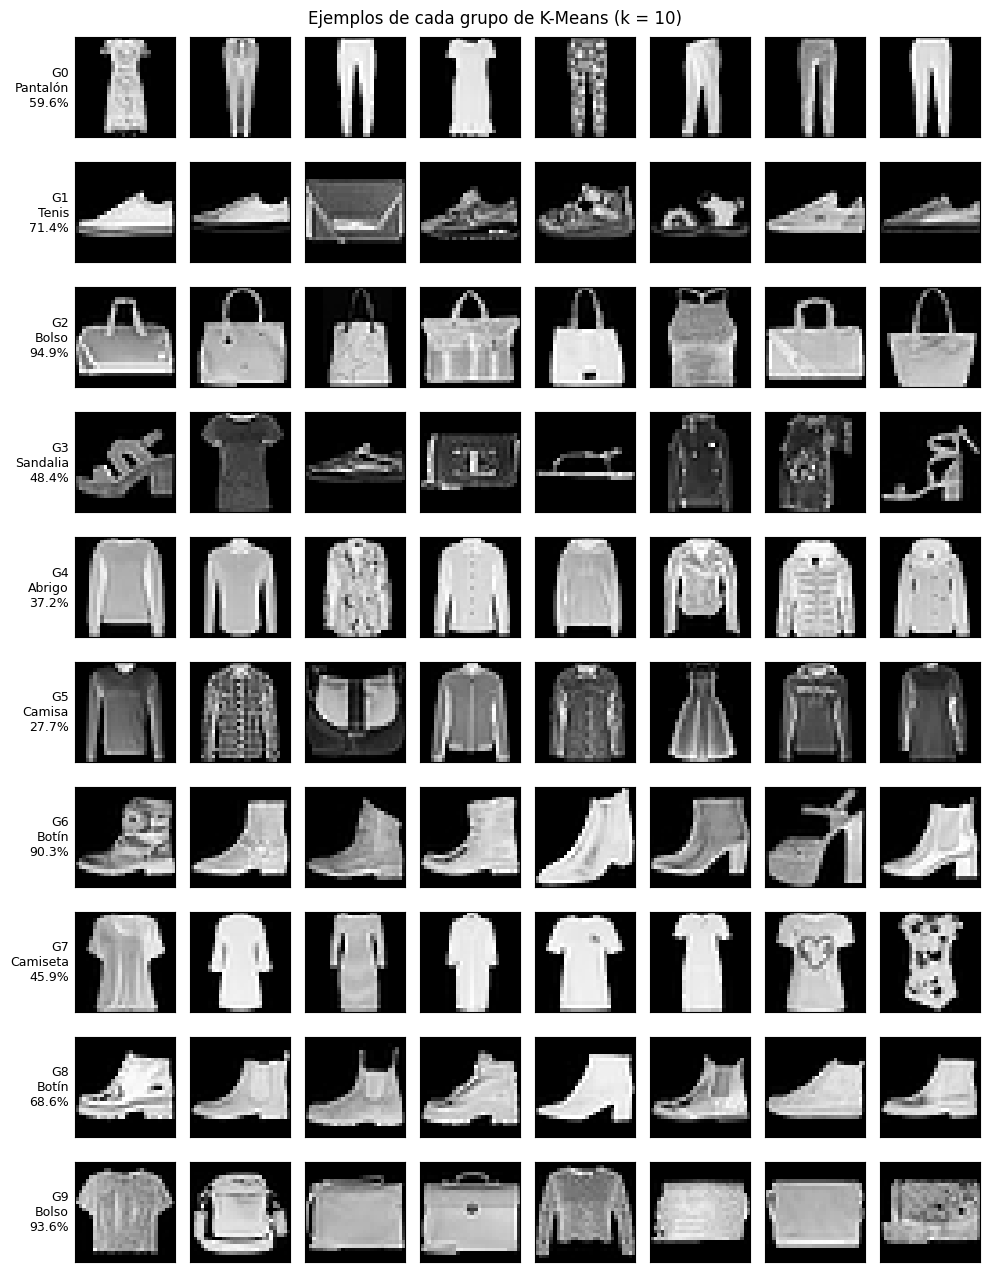

In [ ]:
rng = np.random.default_rng(SEMILLA)
fig, ejes = plt.subplots(10, 8, figsize=(10, 13))
for g in range(10):
    elegidas = rng.choice(np.flatnonzero(grupos_train == g), size=8, replace=False)
    for j, indice in enumerate(elegidas):
        ejes[g, j].imshow(X_train[indice], cmap="gray", vmin=0, vmax=1)
        ejes[g, j].set_xticks([]); ejes[g, j].set_yticks([])
    r = resumen_grupos[g]
    ejes[g, 0].set_ylabel(f"G{g}\n{r['categoria_mayoritaria']}\n{r['porcentaje_mayoritaria']}%",
                          rotation=0, ha="right", va="center", fontsize=9)
fig.suptitle("Ejemplos de cada grupo de K-Means (k = 10)")
fig.tight_layout()
guardar_figura_ns(fig, "kmeans_ejemplos_grupos.png")
plt.show(); plt.close(fig)

**Visualización t-SNE:**

    t-SNE proyecta las 50 componentes en dos dimensiones para ver qué prendas quedan cerca. Se usa una muestra de 3,000
    imágenes de entrenamiento porque t-SNE es lento con las 48,000. t-SNE sirve para explorar visualmente: las distancias
    grandes entre zonas del mapa no deben interpretarse literalmente.

    A la izquierda, los colores son las categorías reales; a la derecha, los grupos de K-Means.

t-SNE calculado en 18.8 s


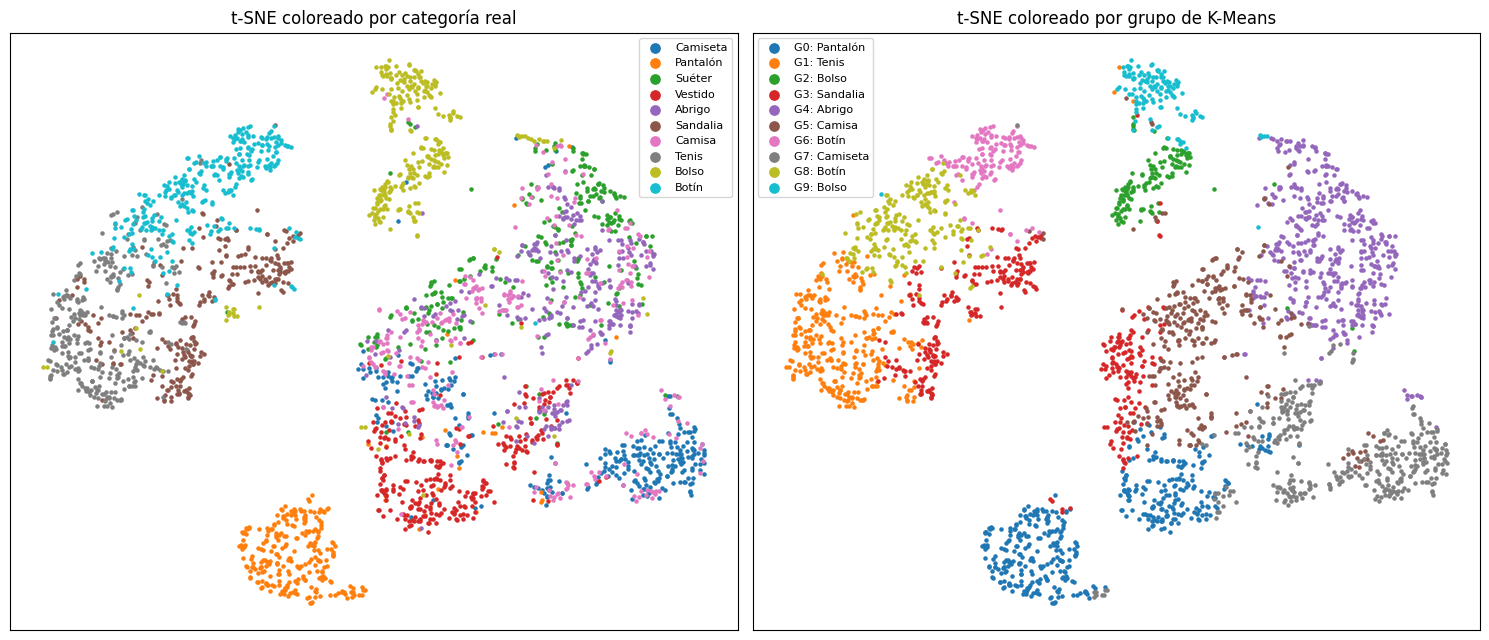

In [ ]:
from sklearn.manifold import TSNE

rng = np.random.default_rng(SEMILLA)
muestra_tsne = rng.choice(len(Z_train), size=3000, replace=False)
inicio = time.time()
tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto",
            max_iter=1000, random_state=SEMILLA)
mapa = tsne.fit_transform(Z_train[muestra_tsne])
print(f"t-SNE calculado en {time.time() - inicio:.1f} s")

colores = plt.get_cmap("tab10")
fig, ejes = plt.subplots(1, 2, figsize=(15, 6.5))
for c in range(10):
    sel = y_train[muestra_tsne] == c
    ejes[0].scatter(mapa[sel, 0], mapa[sel, 1], s=5, color=colores(c), label=CATEGORIAS[c])
    sel = grupos_train[muestra_tsne] == c
    ejes[1].scatter(mapa[sel, 0], mapa[sel, 1], s=5, color=colores(c),
                    label=f"G{c}: {resumen_grupos[c]['categoria_mayoritaria']}")
ejes[0].set_title("t-SNE coloreado por categoría real")
ejes[1].set_title("t-SNE coloreado por grupo de K-Means")
for eje in ejes:
    eje.set_xticks([]); eje.set_yticks([])
    eje.legend(markerscale=3, fontsize=8, loc="best")
fig.tight_layout()
guardar_figura_ns(fig, "tsne_categorias_y_grupos.png")
plt.show(); plt.close(fig)

**Descargar los resultados:**

    Crea un ZIP con las tablas y gráficas de este notebook. Descarga también el notebook ejecutado
    (Archivo > Descargar > `.ipynb`).

In [ ]:
import zipfile

ruta_zip = Path("StyleBot_05_no_supervisado.zip")
with zipfile.ZipFile(ruta_zip, "w", zipfile.ZIP_DEFLATED) as comprimido:
    for ruta in sorted(CARPETA_NO_SUPERVISADO.rglob("*")):
        if ruta.is_file():
            comprimido.write(ruta, ruta.relative_to(CARPETA_NO_SUPERVISADO))
print("Archivo preparado:", ruta_zip.resolve())

try:
    from google.colab import files
except ImportError:
    print("Fuera de Colab: abre el ZIP en la ruta indicada arriba.")
else:
    files.download(str(ruta_zip))

Archivo preparado: /content/StyleBot_05_no_supervisado.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **6. Sistema de recomendación**

    Búsqueda de prendas similares mediante características de las imágenes.

    - Responsable: Luis Ángel Mendosa Gaytan
    - Estado: Completo
    - Archivo del que proviene el trabajo: 06_sistema_recomendacion.ipynb

**Recomendador de prendas similares:**

El **catálogo** son las 48,000 imágenes de entrenamiento. Para una imagen de consulta:

1. Se aplana a 784 píxeles y se transforma con el mismo PCA.
2. Se calculan las distancias a todas las prendas del catálogo.
3. Se devuelven las cinco más cercanas.

Las consultas vienen de validación o prueba, así que nunca son parte del catálogo. El recomendador no usa etiquetas; la categoría solo aparece en los títulos para revisar el resultado.Recomendador de prendas similares

El **catálogo** son las 48,000 imágenes de entrenamiento. Para una imagen de consulta:

1. Se aplana a 784 píxeles y se transforma con el mismo PCA.
2. Se calculan las distancias a todas las prendas del catálogo.
3. Se devuelven las cinco más cercanas.

Las consultas vienen de validación o prueba, así que nunca son parte del catálogo. El recomendador no usa etiquetas; la categoría solo aparece en los títulos para revisar el resultado.

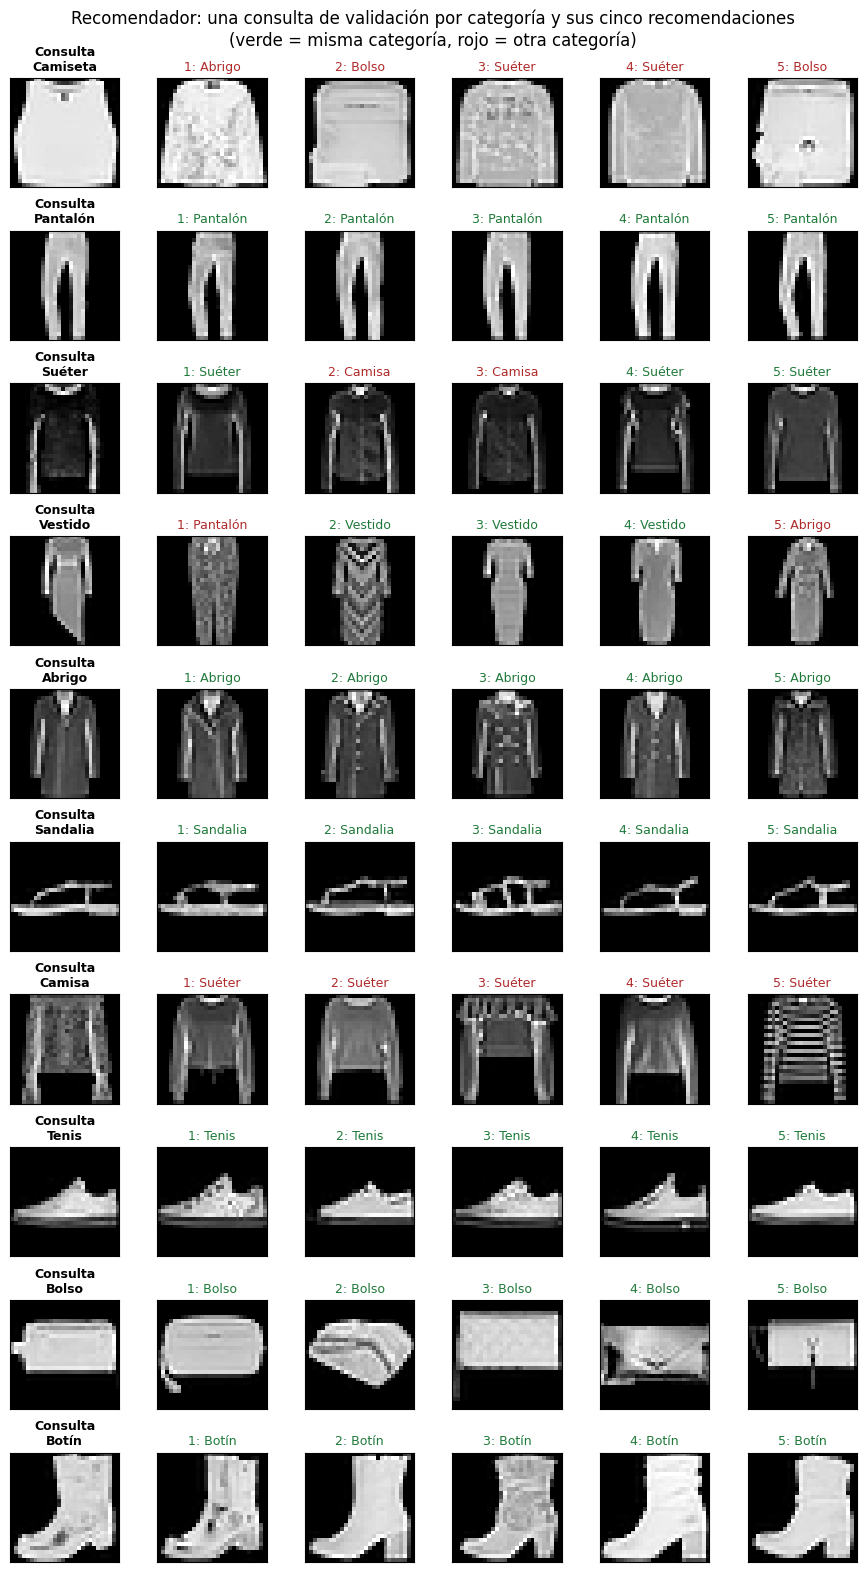

In [ ]:
indice_pca_coseno = construir_recomendador(Z_train, metrica="cosine")

def recomendar_prendas(imagen, k=5):
    """Recibe una imagen 28 x 28 con píxeles entre 0 y 1 y devuelve posiciones del catálogo."""
    z = pca.transform(imagen.reshape(1, -1))
    return recomendar(indice_pca_coseno, z, k)[0]

def mostrar_recomendaciones(ejes_fila, imagen, categoria_consulta, posiciones):
    ejes_fila[0].imshow(imagen, cmap="gray", vmin=0, vmax=1)
    ejes_fila[0].set_title(f"Consulta\n{CATEGORIAS[categoria_consulta]}", fontsize=9, fontweight="bold")
    for j, p in enumerate(posiciones, start=1):
        acierto = y_train[p] == categoria_consulta
        ejes_fila[j].imshow(X_train[p], cmap="gray", vmin=0, vmax=1)
        ejes_fila[j].set_title(f"{j}: {CATEGORIAS[y_train[p]]}", fontsize=9,
                               color="#1f7a3a" if acierto else "#b02a2a")
    for eje in ejes_fila:
        eje.set_xticks([]); eje.set_yticks([])

# Una consulta de cada categoría, tomada de validación
rng = np.random.default_rng(SEMILLA)
fig, ejes = plt.subplots(10, 6, figsize=(9, 16))
for c in range(10):
    consulta = rng.choice(np.flatnonzero(y_val == c))
    mostrar_recomendaciones(ejes[c], X_val[consulta], y_val[consulta], recomendar_prendas(X_val[consulta]))
fig.suptitle("Recomendador: una consulta de validación por categoría y sus cinco recomendaciones\n"
             "(verde = misma categoría, rojo = otra categoría)")
fig.tight_layout()
guardar_figura_ns(fig, "recomendador_ejemplos_validacion.png")
plt.show(); plt.close(fig)

**Evaluación con Precision@5:**

Precision@5 = de las cinco prendas recomendadas, qué fracción es de la misma categoría que la consulta. Se promedia sobre todas las consultas. Si se recomendara al azar, el valor esperado es 0.10 porque hay 10 categorías equilibradas.

**Comparación de variantes en validación:**

Se comparan cuatro variantes con las 12,000 imágenes de validación como consultas. La que obtenga mayor Precision@5 aquí es la que se evaluará en prueba. Las categorías solo sirven para medir cada variante completa; no modifican qué prendas recomienda ninguna de ellas.

In [ ]:
X_train_vec = X_train_flat_ns
indice_pixeles = construir_recomendador(X_train_vec, metrica="cosine")
indice_pca_euclidiana = construir_recomendador(Z_train, metrica="euclidean")

VARIANTES = {
    "Píxeles 784 + coseno": lambda X, Z, G: recomendar(indice_pixeles, a_vectores(X), 5),
    "PCA 50 + euclidiana": lambda X, Z, G: recomendar(indice_pca_euclidiana, Z, 5),
    "PCA 50 + coseno": lambda X, Z, G: recomendar(indice_pca_coseno, Z, 5),
    "PCA 50 + coseno, mismo grupo K-Means": lambda X, Z, G: recomendar_mismo_grupo(Z_train, grupos_train, Z, G, 5),
}

def precision_aleatoria(y_consultas, repeticiones=5):
    valores = [precision_en_k(y_consultas, y_train,
                              recomendaciones_aleatorias(len(y_consultas), len(y_train), 5, semilla=SEMILLA + r))
               for r in range(repeticiones)]
    return float(np.mean(valores)), float(np.std(valores))

comparacion_val = []
for nombre, funcion in VARIANTES.items():
    inicio = time.time()
    posiciones = funcion(X_val, Z_val, grupos_val)
    p5 = precision_en_k(y_val, y_train, posiciones)
    comparacion_val.append({"variante": nombre, "precision_at_5": round(p5, 4),
                            "segundos": round(time.time() - inicio, 1)})
    print(f"{nombre:38} Precision@5 = {p5:.4f}")

media, desv = precision_aleatoria(y_val)
comparacion_val.append({"variante": "Aleatorio (media de 5 semillas)", "precision_at_5": round(media, 4), "segundos": 0})
print(f"{'Aleatorio (media de 5 semillas)':38} Precision@5 = {media:.4f} ± {desv:.4f}")
guardar_tabla_ns("recomendador_comparacion_validacion.csv", comparacion_val)

VARIANTE_ELEGIDA = max(comparacion_val[:-1], key=lambda f: f["precision_at_5"])["variante"]
print("\nVariante elegida con validación:", VARIANTE_ELEGIDA)

Píxeles 784 + coseno                   Precision@5 = 0.8283
PCA 50 + euclidiana                    Precision@5 = 0.8252
PCA 50 + coseno                        Precision@5 = 0.8321
PCA 50 + coseno, mismo grupo K-Means   Precision@5 = 0.8287
Aleatorio (media de 5 semillas)        Precision@5 = 0.1001 ± 0.0010

Variante elegida con validación: PCA 50 + coseno


**Evaluación final en prueba:**

Se usa una sola vez, con la variante elegida en validación. Las 10,000 imágenes de prueba son las consultas y el catálogo sigue siendo entrenamiento. También se calcula la Precision@5 por categoría.

Prueba, PCA 50 + coseno: Precision@5 = 0.8211
Prueba, aleatorio (5 semillas): Precision@5 = 0.1002 ± 0.0016
Mejora sobre el azar: 8.2 veces

Categoría  | Recomendador | Aleatorio
Camiseta   |        0.761 |     0.095
Pantalón   |        0.963 |     0.104
Suéter     |        0.709 |     0.098
Vestido    |        0.832 |     0.103
Abrigo     |        0.714 |     0.106
Sandalia   |        0.873 |     0.103
Camisa     |        0.556 |     0.098
Tenis      |        0.910 |     0.097
Bolso      |        0.954 |     0.099
Botín      |        0.939 |     0.109


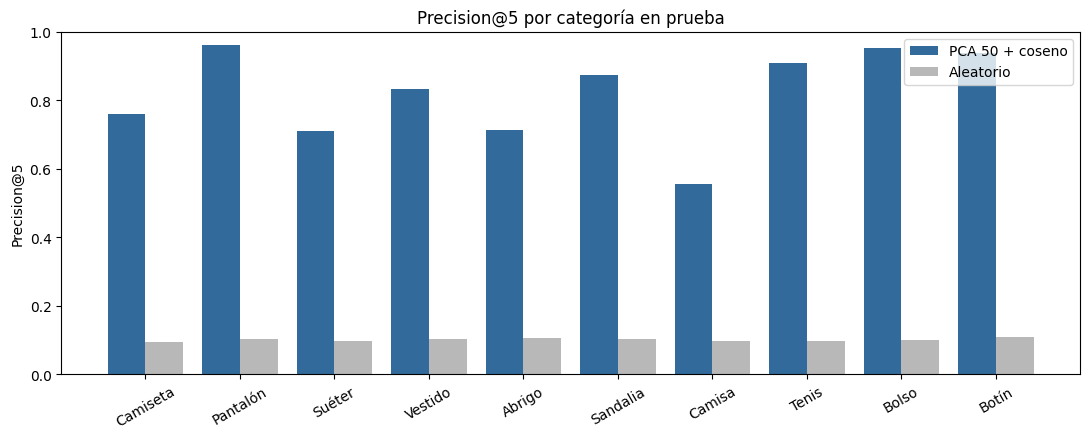

In [ ]:
grupos_test = kmeans.predict(Z_test)
posiciones_test = VARIANTES[VARIANTE_ELEGIDA](X_test, Z_test, grupos_test)
aciertos_test = aciertos(y_test, y_train, posiciones_test)
p5_test = float(aciertos_test.mean())
media_azar, desv_azar = precision_aleatoria(y_test)
posiciones_azar = recomendaciones_aleatorias(len(y_test), len(y_train), 5, semilla=SEMILLA)
aciertos_azar = aciertos(y_test, y_train, posiciones_azar)

print(f"Prueba, {VARIANTE_ELEGIDA}: Precision@5 = {p5_test:.4f}")
print(f"Prueba, aleatorio (5 semillas): Precision@5 = {media_azar:.4f} ± {desv_azar:.4f}")
print(f"Mejora sobre el azar: {p5_test / media_azar:.1f} veces")

resultado_final = [
    {"conjunto": "prueba", "variante": VARIANTE_ELEGIDA, "precision_at_5": round(p5_test, 4)},
    {"conjunto": "prueba", "variante": "Aleatorio (media de 5 semillas)", "precision_at_5": round(media_azar, 4)},
]
guardar_tabla_ns("recomendador_resultado_prueba.csv", resultado_final)

por_categoria = []
print("\nCategoría  | Recomendador | Aleatorio")
for c in range(10):
    sel = y_test == c
    fila = {"id": c, "categoria": CATEGORIAS[c],
            "precision_at_5_recomendador": round(float(aciertos_test[sel].mean()), 4),
            "precision_at_5_aleatorio": round(float(aciertos_azar[sel].mean()), 4)}
    por_categoria.append(fila)
    print(f"{CATEGORIAS[c]:10} | {fila['precision_at_5_recomendador']:12.3f} | {fila['precision_at_5_aleatorio']:9.3f}")
guardar_tabla_ns("recomendador_precision_por_categoria_prueba.csv", por_categoria)

fig, ax = plt.subplots(figsize=(11, 4.5))
posiciones_x = np.arange(10)
ax.bar(posiciones_x - 0.2, [f["precision_at_5_recomendador"] for f in por_categoria], 0.4,
       label=VARIANTE_ELEGIDA, color="#326b9b")
ax.bar(posiciones_x + 0.2, [f["precision_at_5_aleatorio"] for f in por_categoria], 0.4,
       label="Aleatorio", color="#b8b8b8")
ax.set_xticks(posiciones_x, CATEGORIAS, rotation=30)
ax.set_ylim(0, 1); ax.set_ylabel("Precision@5")
ax.set_title("Precision@5 por categoría en prueba")
ax.legend()
fig.tight_layout()
guardar_figura_ns(fig, "recomendador_precision_por_categoria.png")
plt.show(); plt.close(fig)

**Ejemplos de aciertos y fallos:**

Arriba, consultas de prueba con las cinco recomendaciones correctas; abajo, consultas con más fallos. La tabla siguiente cuenta con qué categorías se confunden más las recomendaciones.

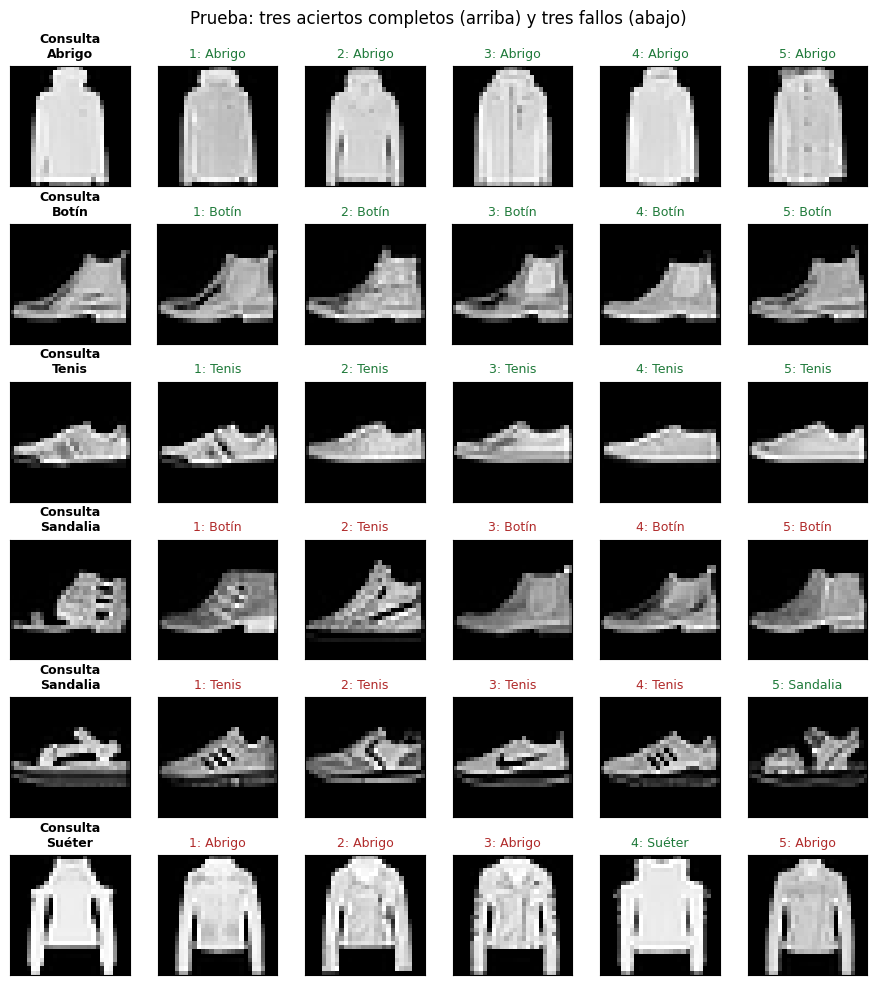

Consultas con 5 de 5 correctas: 63.9%
Consultas con 0 o 1 correctas: 9.5%

Confusiones más frecuentes (consulta -> recomendada):
  Camisa    -> Camiseta    871 (17.4%)
  Camiseta  -> Camisa      806 (16.1%)
  Abrigo    -> Suéter      694 (13.9%)
  Suéter    -> Abrigo      654 (13.1%)
  Suéter    -> Camisa      594 (11.9%)
  Camisa    -> Suéter      587 (11.7%)
  Abrigo    -> Camisa      540 (10.8%)
  Camisa    -> Abrigo      520 (10.4%)
  Sandalia  -> Tenis       362 (7.2%)
  Tenis     -> Botín       319 (6.4%)


In [ ]:
rng = np.random.default_rng(SEMILLA)
n_aciertos = aciertos_test.sum(axis=1)
buenos = rng.choice(np.flatnonzero(n_aciertos == 5), size=3, replace=False)
malos = rng.choice(np.flatnonzero(n_aciertos <= 1), size=3, replace=False)

fig, ejes = plt.subplots(6, 6, figsize=(9, 10))
for fila, consulta in enumerate(np.concatenate([buenos, malos])):
    mostrar_recomendaciones(ejes[fila], X_test[consulta], y_test[consulta], posiciones_test[consulta])
fig.suptitle("Prueba: tres aciertos completos (arriba) y tres fallos (abajo)")
fig.tight_layout()
guardar_figura_ns(fig, "recomendador_aciertos_y_fallos.png")
plt.show(); plt.close(fig)

print(f"Consultas con 5 de 5 correctas: {np.mean(n_aciertos == 5):.1%}")
print(f"Consultas con 0 o 1 correctas: {np.mean(n_aciertos <= 1):.1%}")

confusiones = tabla_contingencia(np.repeat(y_test, 5), y_train[posiciones_test].ravel())
np.fill_diagonal(confusiones, 0)
pares = sorted(((confusiones[a, b], a, b) for a in range(10) for b in range(10) if confusiones[a, b] > 0), reverse=True)[:10]
filas_conf = [{"consulta": CATEGORIAS[a], "recomendada": CATEGORIAS[b], "recomendaciones": int(n),
               "porcentaje_de_la_categoria": round(100 * n / (5 * np.sum(y_test == a)), 1)} for n, a, b in pares]
guardar_tabla_ns("recomendador_confusiones_prueba.csv", filas_conf)
print("\nConfusiones más frecuentes (consulta -> recomendada):")
for f in filas_conf:
    print(f"  {f['consulta']:9} -> {f['recomendada']:9} {f['recomendaciones']:5} ({f['porcentaje_de_la_categoria']}%)")

**Descargar los resultados:**

Crea un ZIP con las tablas y gráficas de este notebook. Descarga también el notebook ejecutado (Archivo > Descargar > `.ipynb`).

In [ ]:
import zipfile

ruta_zip = Path("StyleBot_06_recomendacion.zip")
with zipfile.ZipFile(ruta_zip, "w", zipfile.ZIP_DEFLATED) as comprimido:
    for ruta in sorted(CARPETA_NO_SUPERVISADO.rglob("*")):
        if ruta.is_file():
            comprimido.write(ruta, ruta.relative_to(CARPETA_NO_SUPERVISADO))
print("Archivo preparado:", ruta_zip.resolve())

try:
    from google.colab import files
except ImportError:
    print("Fuera de Colab: abre el ZIP en la ruta indicada arriba.")
else:
    files.download(str(ruta_zip))

Archivo preparado: /content/StyleBot_06_recomendacion.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Fuentes:**

    Scikit-learn. KMeans. https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html
    Scikit-learn. PCA. https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html
    Scikit-learn. TSNE. https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html
    Scikit-learn. NearestNeighbors. https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.NearestNeighbors.html
    Scikit-learn. Evaluación de agrupamiento (ARI, NMI, silueta). https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation
    Manning, Raghavan y Schütze (2008). Introduction to Information Retrieval, cap. 8 (precisión en los primeros k resultados). https://nlp.stanford.edu/IR-book/
    Van der Maaten y Hinton (2008). Visualizing Data using t-SNE. Journal of Machine Learning Research, 9.
    Equipo StyleBot. 02_caracteristicas.ipynb (aplanado y PCA reutilizados) y 01_datos.ipynb (carga común).
    Xiao, Rasul y Vollgraf (2017). Fashion-MNIST. https://github.com/zalandoresearch/fashion-mnist

# **7. Evaluación y comparación general**

    Función de evaluación común y la tabla comparativa.

    - Responsable: Jacqueline Soto
    - Estado: Completo
    - Archivo del que proviene el trabajo: E1_StyleBot.ipynb

**Importar las herramientas necesarias:**

    En esta sección se importan las herramientas de la biblioteca sklearn.metrics, que contiene funciones utilizadas
    para evaluar qué tan bien está funcionando un modelo de inteligencia artificial.

    Cada función permite medir un aspecto diferente de las predicciones que realiza el modelo:
    -accuracy_score: Calcula el porcentaje de predicciones correctas del modelo.
    -precision_score: Mide qué tan confiables son las predicciones positivas del modelo.
    -recall_score: Mide qué tantas respuestas correctas logró encontrar el modelo.
    -f1_score: Combina la precisión y el recall para obtener una medida general del rendimiento.
    -confusion_matrix: Genera una tabla que permite comparar las respuestas reales con las predicciones del modelo.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

**Crear la función y calcular las métricas de evaluación:**

    En esta sección se crea una función llamada evaluar_modelo, que recibe dos parámetros: etiquetas_reales, que contiene
    las respuestas correctas, y predicciones, que contiene los resultados generados por el modelo.

    Dentro de la función se calculan cinco métricas para evaluar su rendimiento:
    -Accuracy: Calcula el porcentaje total de predicciones correctas.
    -Precision macro: Calcula qué tan confiables son las predicciones de cada clase y obtiene el promedio, dando la misma
    importancia a todas.
    -Recall macro: Calcula cuántos ejemplos de cada clase logró identificar correctamente el modelo y obtiene el promedio
    de todas las clases.
    -F1 macro: Combina Precision y Recall para obtener una medida general del rendimiento de cada clase y después calcula
    su promedio.
    -Matriz de confusión: Genera una tabla que permite identificar cuántas predicciones fueron correctas y en cuáles se
    equivocó el modelo.

    Para las métricas Precision, Recall y F1 se utilizan algunos parámetros adicionales:
    -labels=list(range(10)): Indica que se deben evaluar las 10 clases, identificadas con números del 0 al 9.
    -average='macro': Calcula el promedio de los resultados de todas las clases, dándoles la misma importancia.
    -zero_division=0: Establece el resultado en 0 cuando no es posible realizar alguno de los cálculos.

    Cada resultado se guarda en una variable para poder utilizarlo posteriormente. De esta manera, la función permite
    evaluar diferentes modelos utilizando los mismos criterios, sin necesidad de repetir todo el código.

    En esta última sección se utiliza return para devolver todos los resultados obtenidos durante la evaluación del modelo.

In [2]:
def evaluar_modelo(etiquetas_reales, predicciones):

    # Calcular Accuracy
    accuracy = accuracy_score(
        etiquetas_reales,
        predicciones
    )

    # Calcular Precisión macro
    precision = precision_score(
        etiquetas_reales,
        predicciones,
        labels=list(range(10)),
        average='macro',
        zero_division=0
    )

    # Calcular Recall macro
    recall = recall_score(
        etiquetas_reales,
        predicciones,
        labels=list(range(10)),
        average='macro',
        zero_division=0
    )

    # Calcular F1 macro
    f1 = f1_score(
        etiquetas_reales,
        predicciones,
        labels=list(range(10)),
        average='macro',
        zero_division=0
    )

    # Calcular matriz de confusión
    matriz = confusion_matrix(
        etiquetas_reales,
        predicciones,
        labels=list(range(10))
    )

    return {
        'Accuracy': accuracy,
        'Precision macro': precision,
        'Recall macro': recall,
        'F1 macro': f1,
        'Matriz de confusion': matriz
    }



In [25]:
# Mostrar la tabla comparativa de los modelos evaluados en prueba
display(tabla_final.round(4))

,candidato,accuracy,precision_ponderada,recall_ponderado,f1_ponderado,precision_macro,recall_macro,f1_macro
0,Regresión logística (HOG + Hu),0.8841,0.8838,0.8841,0.8839,0.8838,0.8841,0.8839
1,Random Forest (Píxeles crudos),0.8757,0.8746,0.8757,0.8743,0.8746,0.8757,0.8743
2,Regresión logística (Píxeles crudos),0.8399,0.8387,0.8399,0.8391,0.8387,0.8399,0.8391
3,SVM lineal (Píxeles crudos),0.8386,0.8359,0.8386,0.8360,0.8359,0.8386,0.8360


**Fuentes:**

    Shafara, J. (2024, febrero). Classification metrics practice. DATAIDEA. https://science.dataidea.org/Extras/classification_metrics/

    Sarkar, T. (2026, 26 de enero). Introduction to Scikit-learn: A Python machine learning package. Part II: Comparing ML models. National Institutes of Health. https://bioinformatics.ccr.cancer.gov/docs/btep-coding-club/CC2026/scikit-learn-part2/Intro_to_scikit_learn_BTEP_part2.pdf

    Scikit-learn Developers. (s. f.). Metrics and scoring: Quantifying the quality of predictions. Scikit-learn. https://scikit-learn.org/stable/modules/model_evaluation.html

    Scikit-learn Developers. (s. f.). sklearn.metrics API reference. Scikit-learn. https://scikit-learn.org/stable/api/sklearn.metrics.html

# **8. Resultados y conclusiones**

    Comparación de resultados y observaciones del equipo.

    - Responsable: Jacqueline Soto
    - Estado: Completo
    - Archivo del que proviene el trabajo: E1_StyleBot.ipynb







**Análisis de Resultados Preliminares:**

- Rendimiento Base: El modelo de Random Forest entrenado con píxeles crudos obtuvo el mejor rendimiento inicial, alcanzando un accuracy de 0.8841.

- Impacto de PCA: La reducción de dimensionalidad demostró ser altamente efectiva para optimizar los tiempos de ejecución en los modelos lineales. El tiempo de entrenamiento de la Regresión Logística se redujo de 53.2 segundos a solo 1.59 segundos, y el de SVM Lineal pasó de 179.2 a 7.87 segundos, sacrificando en ambos casos menos de un 1% de precisión.

**Optimización y Validación Cruzada:**

En la fase de ajuste de hiperparámetros (GridSearchCV) se incorporó una representación avanzada de los datos que combinó Histogramas de Gradientes Orientados (HOG) con Momentos Invariantes de Hu. Los resultados definitivos de la validación cruzada fueron:

- Regresión Logística (HOG + Hu): Se posicionó como el mejor modelo global con un F1-Macro de 0.8599, un accuracy de 0.8900 y un tiempo de ajuste competitivo de 38.22 segundos utilizando el hiperparámetro C=0.01.

- Random Forest (Píxeles crudos): Se mantuvo en segundo lugar (F1-Macro de 0.8539) utilizando n_estimators=150 y max_depth=null, pero con un coste computacional significativamente mayor (173.49 segundos).

- SVM Lineal (Píxeles crudos): Resultó ser el modelo menos eficiente en esta etapa, requiriendo 824.65 segundos para su ajuste y registrando la métrica F1-Macro más baja entre los finalistas (0.8178).

**Conclusiones del Equipo:**

- La ingeniería de características superó a la fuerza bruta: La extracción de bordes, contornos locales (HOG) y forma geométrica global (Momentos de Hu) demostró ser una representación de datos muy superior al uso directo de píxeles. Esto permitió que un modelo lineal simple como la Regresión Logística lograra superar en precisión a algoritmos más complejos como Random Forest.

- Selección del Modelo Final: La Regresión Logística entrenada con características HOG + Hu es el candidato definitivo para el sistema StyleBot. Este modelo ofrece el mejor equilibrio técnico del proyecto: maximiza la capacidad de identificar correctamente las prendas de ropa (accuracy del 89%) y mantiene una alta eficiencia computacional que facilitará su futura puesta en producción.